# Statistical Analysis of Image Deblurring Methods

This notebook analyzes the performance of different deblurring methods (Pseudoinverse, Wiener, DeblurGANv2) using a comprehensive statistical approach. We will explore descriptive statistics, hypothesis testing, confidence intervals, regression analysis, and visualizations to understand the strengths and weaknesses of each method.


### Single image example

In this section, we show a single-image comparison example using the Wiener deblurring method (with and without kernel knowledge). The `show_comparison` function displays the original image and the deblurred results for different blur types, allowing for an intuitive assessment of the method's effect.
As can be seen from the images, if the method knows the blur kernel, the deblurring result is visibly better compared to the case where the kernel is not known.


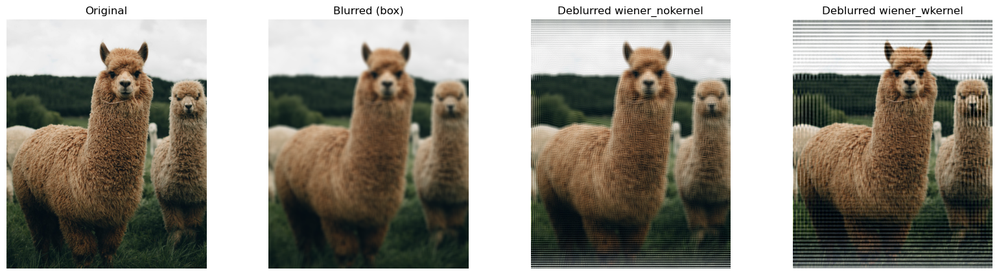

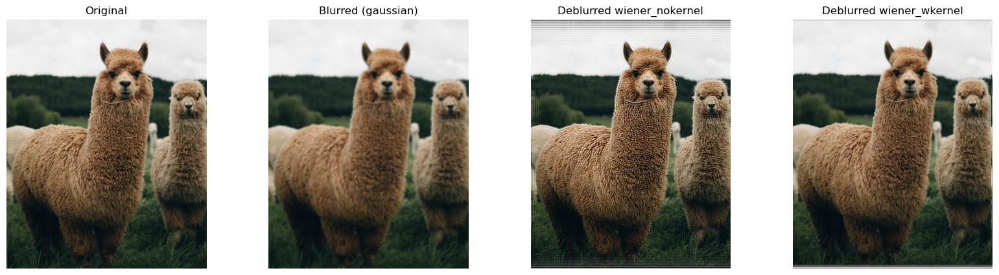

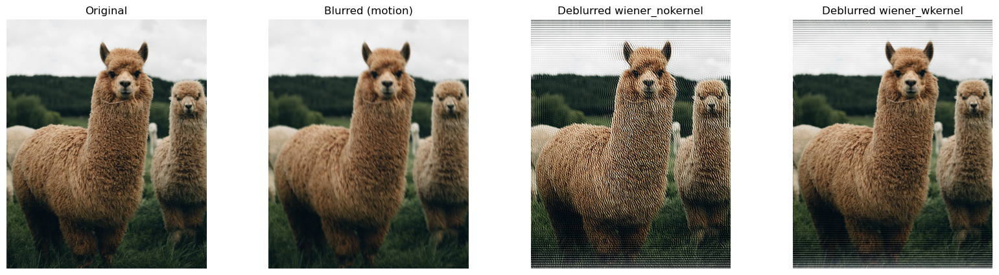

In [1]:
from common.img_output import show_comparison
from common.config import BLUR_TYPES

single_image_key = "000000845"
single_image_method = "wiener"

show_comparison(
    key=single_image_key, 
    method=single_image_method, 
    blur_types=BLUR_TYPES, 
    cropped=False
)


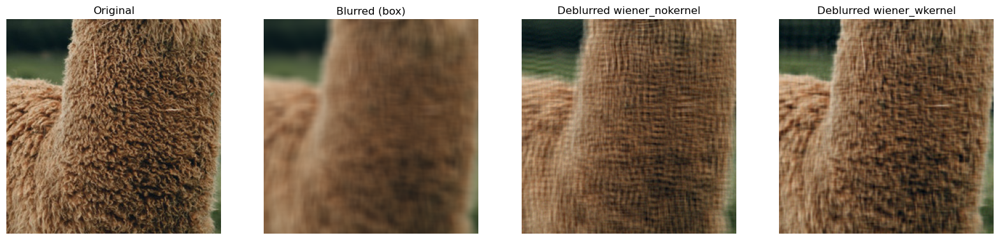

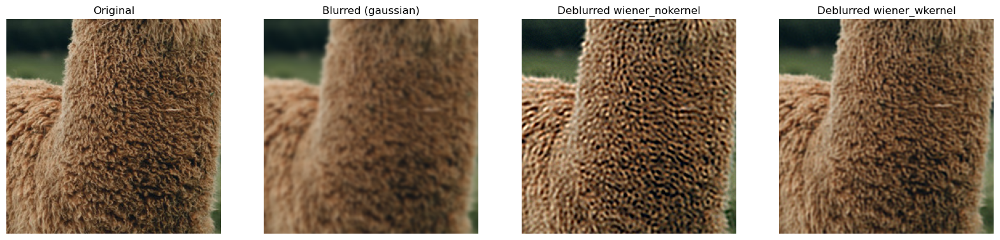

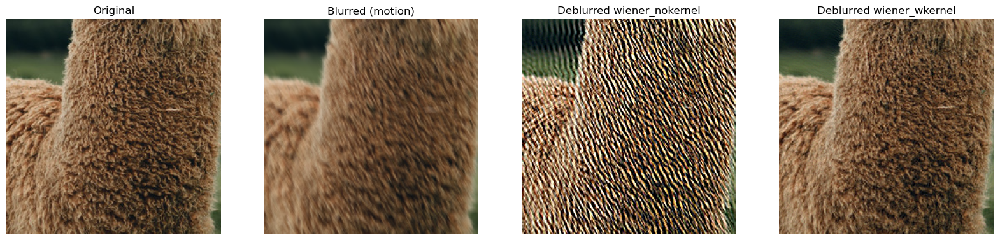

In [2]:
show_comparison(
    key=single_image_key, 
    method=single_image_method, 
    blur_types=BLUR_TYPES, 
    cropped=True
)

### Data Loading and Preprocessing

In this section, we load the original image dataset and the metric results for each deblurring method. The original dataframe is merged with each method's metrics dataframe using the image key. For each approach, we compute the average value of each metric across all blur types (box, gaussian, motion), resulting in a single metric column per method. This preprocessing step ensures that the data is ready for subsequent statistical analysis and comparisons.


In [3]:
import pandas as pd
import numpy as np

from common.config import IDPA_DATASET, WIENER_NOKERNEL_DATASET, WIENER_WKERNEL_DATASET, DEBLURGANV2_DATASET, PSEUDOINVERSE_NOKERNEL_DATASET, PSEUDOINVERSE_WKERNEL_DATASET
from common.config import METRIC_TYPES, BLUR_TYPES

original_df = pd.read_parquet(IDPA_DATASET).dropna()

dfs = {
    'pseudoinverse_nokernel': pd.read_parquet(PSEUDOINVERSE_NOKERNEL_DATASET),
    'pseudoinverse_wkernel': pd.read_parquet(PSEUDOINVERSE_WKERNEL_DATASET),
    'wiener_nokernel': pd.read_parquet(WIENER_NOKERNEL_DATASET),
    'wiener_wkernel': pd.read_parquet(WIENER_WKERNEL_DATASET),
    'deblurganv2': pd.read_parquet(DEBLURGANV2_DATASET)
}

print(f"Image parameters: {original_df.shape}")
display(original_df.head(3))

print(f"Metrics for deblurganv2: {dfs["deblurganv2"].shape}")
display(dfs["deblurganv2"].head(3))

for k in dfs.keys():
    dfs[k] = original_df.merge(dfs[k], on='key')

for df in dfs.values():
    for metric in METRIC_TYPES:
        cols = [f'{metric}_{b}' for b in BLUR_TYPES if f'{metric}_{b}' in df.columns]
        df[metric] = df[cols].mean(axis=1)

Image parameters: (950, 16)


,url,category,key,width,height,exif,aspect_ratio,size,rms_contrast,sobel_edge_strength,canny_edge_density,box_size,gaussian_sigma,gaussian_size,motion_length,motion_angle
2,http://411posters.com/wp-content/uploads/2011/...,poster,000000382,1300.0,1728.0,{},0.752315,3169036.0,0.373365,54.414061,0.139681,14.0,2.079159,13.0,13.0,232.710817
5,http://a.mktgcdn.com/p/0LhPt4Nq5I-vk_mT8U64np5...,withchar,000000931,1680.0,1120.0,{},1.500000,3369749.0,0.302635,61.659178,0.114193,5.0,0.966656,7.0,17.0,112.800705
6,http://a1.espncdn.com/photo/2012/1113/mag_odog...,complex,000000558,2048.0,1280.0,{},1.600000,3899907.0,0.220292,60.462335,0.090309,12.0,2.335230,15.0,16.0,152.963697


Metrics for deblurganv2: (950, 16)


,key,proctime_box,proctime_gaussian,proctime_motion,ssim_box,psnr_box,lpips_box,gmsd_box,ssim_gaussian,psnr_gaussian,lpips_gaussian,gmsd_gaussian,ssim_motion,psnr_motion,lpips_motion,gmsd_motion
0,000000000,0.771006,0.227473,0.227028,0.624878,21.736350,0.063853,0.269811,0.618547,21.525129,0.089766,0.278274,0.789718,24.130607,0.005149,0.174958
1,000000002,0.243786,0.229896,0.233648,0.592647,22.730560,0.006872,0.227930,0.655491,23.634710,0.010482,0.216396,0.536058,21.578249,0.040192,0.224285
2,000000003,0.220997,0.182720,0.180572,0.716148,25.098564,0.004474,0.189143,0.540464,21.949155,0.144286,0.256134,0.667576,23.922039,0.035748,0.192016


In [4]:
top_proctime_df = dfs["deblurganv2"].nlargest(5, "proctime")[["key", "proctime", "proctime_box", "proctime_gaussian", "proctime_motion", "size", "width", "height"]]

outlier_idxs = top_proctime_df.index

for df_name in dfs.keys():
    dfs[df_name] = dfs[df_name].drop(outlier_idxs)

## ANALYSIS


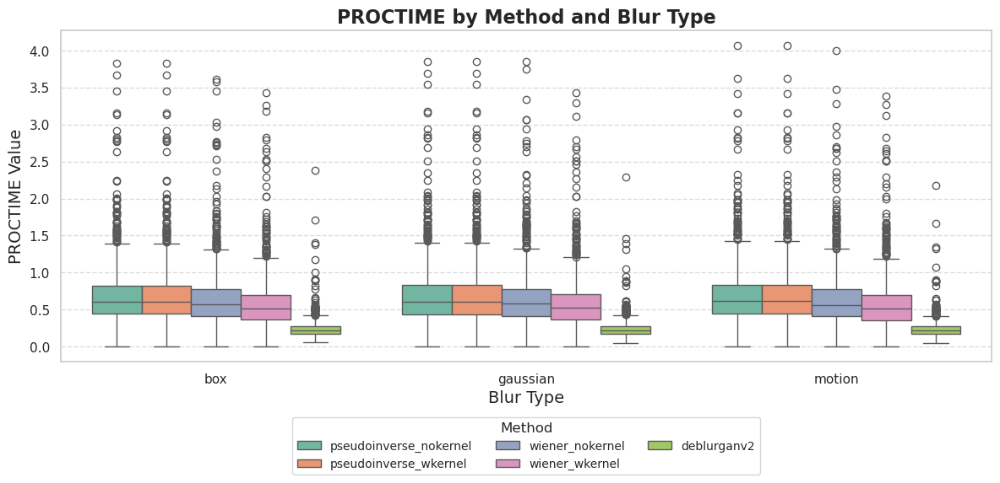

ANOVA Gaussian PROCTIME: F=228.01, p=3.275e-179
Descriptive statistics for PROCTIME:



count      mean       std       min  \
blur     method                                                        
box      deblurganv2             945.0  0.239549  0.150479  0.059382   
         pseudoinverse_nokernel  945.0  0.696556  0.444381  0.003101   
         pseudoinverse_wkernel   945.0  0.696556  0.444381  0.003101   
         wiener_nokernel         945.0  0.655113  0.429660  0.003225   
         wiener_wkernel          945.0  0.595793  0.401518  0.002487   
gaussian deblurganv2             945.0  0.239095  0.143437  0.043399   
         pseudoinverse_nokernel  945.0  0.692347  0.446385  0.003167   
         pseudoinverse_wkernel   945.0  0.692347  0.446385  0.003167   
         wiener_nokernel         945.0  0.664563  0.439021  0.003450   
         wiener_wkernel          945.0  0.597469  0.399309  0.002435   
motion   deblurganv2             945.0  0.236605  0.143114  0.043471   
         pseudoinverse_nokernel  945.0  0.700601  0.447303  0.003123   
         pseudoinverse_wkernel   945.0  0.700601  0.447303  0.003123   
         wiener_nokernel         945.0  0.650781  0.426071  0.002816   
         wiener_wkernel          945.0  0.591816  0.398157  0.002432   

                                      25%       50%       75%       max  
blur     method                                                          
box      deblurganv2             0.175043  0.213260  0.273509  2.384044  
         pseudoinverse_nokernel  0.440453  0.608063  0.824878  3.822486  
         pseudoinverse_wkernel   0.440453  0.608063  0.824878  3.822486  
         wiener_nokernel         0.408491  0.571736  0.771568  3.607599  
         wiener_wkernel          0.362938  0.516055  0.701220  3.433648  
gaussian deblurganv2             0.177822  0.215767  0.276814  2.287336  
         pseudoinverse_nokernel  0.437174  0.606593  0.829851  3.847519  
         pseudoinverse_wkernel   0.437174  0.606593  0.829851  3.847519  
         wiener_nokernel         0.410778  0.580706  0.778699  3.850654  
         wiener_wkernel          0.366116  0.520335  0.702787  3.427990  
motion   deblurganv2             0.176777  0.214118  0.269920  2.181084  
         pseudoinverse_nokernel  0.443729  0.614073  0.838659  4.072581  
         pseudoinverse_wkernel   0.443729  0.614073  0.838659  4.072581  
         wiener_nokernel         0.411959  0.563748  0.774340  4.000125  
         wiener_wkernel          0.358609  0.512985  0.701498  3.381966

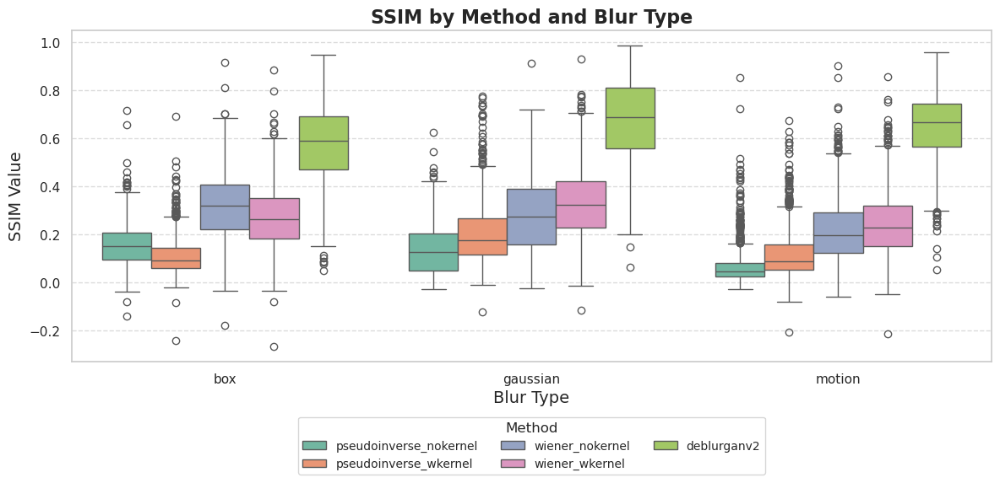

ANOVA Gaussian SSIM: F=2069.42, p=0.000e+00
Descriptive statistics for SSIM:



count      mean       std       min  \
blur     method                                                        
box      deblurganv2             945.0  0.576621  0.159550  0.050667   
         pseudoinverse_nokernel  945.0  0.157720  0.089355 -0.138958   
         pseudoinverse_wkernel   945.0  0.112080  0.079554 -0.241310   
         wiener_nokernel         945.0  0.320116  0.139083 -0.179358   
         wiener_wkernel          945.0  0.273512  0.130439 -0.266220   
gaussian deblurganv2             945.0  0.679654  0.172127  0.065307   
         pseudoinverse_nokernel  945.0  0.137883  0.099664 -0.027396   
         pseudoinverse_wkernel   945.0  0.205797  0.129159 -0.124185   
         wiener_nokernel         945.0  0.282119  0.152144 -0.024312   
         wiener_wkernel          945.0  0.331259  0.146830 -0.116415   
motion   deblurganv2             945.0  0.649095  0.138746  0.053819   
         pseudoinverse_nokernel  945.0  0.068619  0.080590 -0.029118   
         pseudoinverse_wkernel   945.0  0.122359  0.102547 -0.208278   
         wiener_nokernel         945.0  0.219901  0.131230 -0.057947   
         wiener_wkernel          945.0  0.245295  0.133508 -0.214672   

                                      25%       50%       75%       max  
blur     method                                                          
box      deblurganv2             0.470091  0.590618  0.692740  0.948262  
         pseudoinverse_nokernel  0.094274  0.151156  0.209151  0.717562  
         pseudoinverse_wkernel   0.059752  0.091813  0.145460  0.693440  
         wiener_nokernel         0.220462  0.318868  0.406566  0.918613  
         wiener_wkernel          0.183521  0.262211  0.351670  0.885859  
gaussian deblurganv2             0.560165  0.687394  0.812656  0.988984  
         pseudoinverse_nokernel  0.050825  0.127303  0.204205  0.626754  
         pseudoinverse_wkernel   0.116926  0.177744  0.266084  0.777548  
         wiener_nokernel         0.157071  0.273417  0.389500  0.914963  
         wiener_wkernel          0.229016  0.324175  0.421472  0.930632  
motion   deblurganv2             0.566989  0.669053  0.746460  0.960551  
         pseudoinverse_nokernel  0.023498  0.045463  0.079665  0.853196  
         pseudoinverse_wkernel   0.053755  0.088151  0.159482  0.673604  
         wiener_nokernel         0.124173  0.197076  0.290949  0.903753  
         wiener_wkernel          0.151436  0.227327  0.319662  0.857579

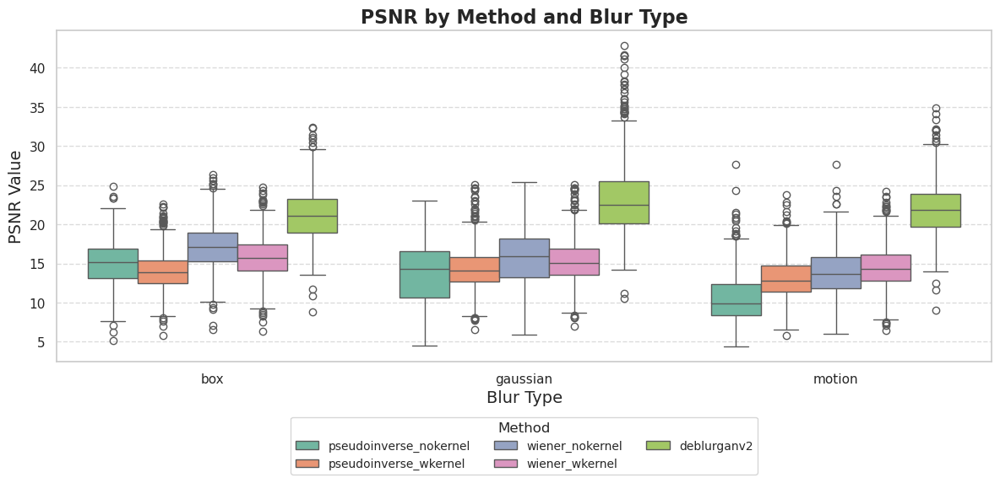

ANOVA Gaussian PSNR: F=1123.85, p=0.000e+00
Descriptive statistics for PSNR:



count       mean       std        min  \
blur     method                                                          
box      deblurganv2             945.0  21.238875  3.216944   8.820094   
         pseudoinverse_nokernel  945.0  15.013341  2.813431   5.161451   
         pseudoinverse_wkernel   945.0  14.060371  2.321488   5.771884   
         wiener_nokernel         945.0  17.058947  2.852167   6.522241   
         wiener_wkernel          945.0  15.773771  2.577955   6.374496   
gaussian deblurganv2             945.0  23.148925  4.452894  10.536612   
         pseudoinverse_nokernel  945.0  13.669335  3.916083   4.523985   
         pseudoinverse_wkernel   945.0  14.331407  2.646430   6.536478   
         wiener_nokernel         945.0  15.571661  3.556010   5.874600   
         wiener_wkernel          945.0  15.238192  2.745247   7.026135   
motion   deblurganv2             945.0  21.902328  3.233108   9.067159   
         pseudoinverse_nokernel  945.0  10.607475  2.966431   4.410310   
         pseudoinverse_wkernel   945.0  13.154304  2.620196   5.819319   
         wiener_nokernel         945.0  13.968605  2.941496   6.038183   
         wiener_wkernel          945.0  14.483837  2.718051   6.470291   

                                       25%        50%        75%        max  
blur     method                                                              
box      deblurganv2             18.895795  21.120137  23.232650  32.418278  
         pseudoinverse_nokernel  13.148129  15.145490  16.878494  24.874313  
         pseudoinverse_wkernel   12.510861  13.891482  15.377222  22.578803  
         wiener_nokernel         15.306178  17.135346  18.984464  26.345808  
         wiener_wkernel          14.131499  15.673598  17.425027  24.793386  
gaussian deblurganv2             20.163002  22.537647  25.464602  42.896303  
         pseudoinverse_nokernel  10.604839  14.355647  16.524991  23.008617  
         pseudoinverse_wkernel   12.712824  14.124528  15.788198  25.092058  
         wiener_nokernel         13.224267  15.895789  18.135803  25.388029  
         wiener_wkernel          13.550703  15.037471  16.877056  25.095790  
motion   deblurganv2             19.648233  21.852450  23.904904  34.828347  
         pseudoinverse_nokernel   8.425301   9.913064  12.374095  27.665516  
         pseudoinverse_wkernel   11.365047  12.852949  14.787797  23.795675  
         wiener_nokernel         11.795591  13.648773  15.823115  27.658205  
         wiener_wkernel          12.767900  14.292577  16.148027  24.259658

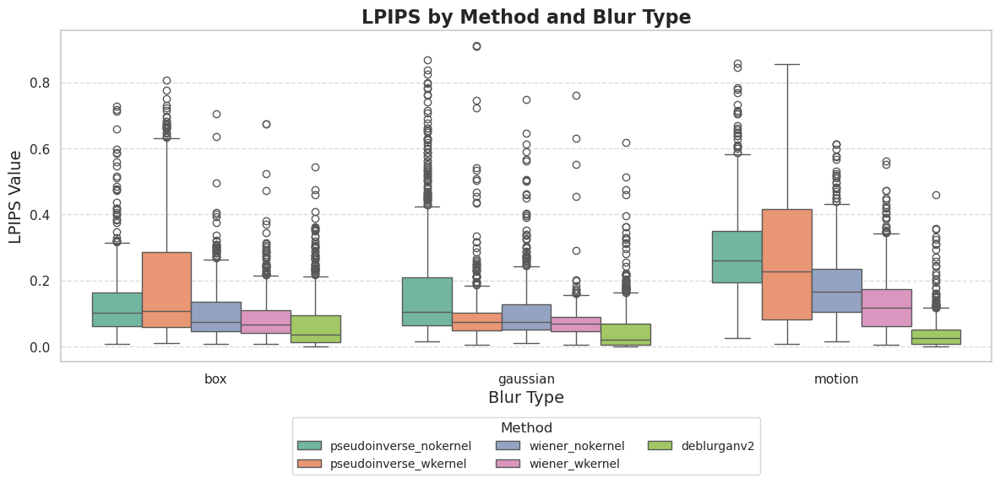

ANOVA Gaussian LPIPS: F=221.18, p=3.074e-174
Descriptive statistics for LPIPS:



count      mean       std       min  \
blur     method                                                        
box      deblurganv2             945.0  0.065096  0.074479  0.001092   
         pseudoinverse_nokernel  945.0  0.126014  0.094351  0.007813   
         pseudoinverse_wkernel   945.0  0.189570  0.176041  0.010211   
         wiener_nokernel         945.0  0.099843  0.074515  0.007371   
         wiener_wkernel          945.0  0.085648  0.068630  0.007387   
gaussian deblurganv2             945.0  0.047902  0.066535  0.000117   
         pseudoinverse_nokernel  945.0  0.166941  0.153196  0.015225   
         pseudoinverse_wkernel   945.0  0.087173  0.076615  0.005619   
         wiener_nokernel         945.0  0.101237  0.082916  0.010894   
         wiener_wkernel          945.0  0.071527  0.048210  0.005647   
motion   deblurganv2             945.0  0.038539  0.046739  0.000395   
         pseudoinverse_nokernel  945.0  0.281086  0.127911  0.026539   
         pseudoinverse_wkernel   945.0  0.264319  0.201202  0.006879   
         wiener_nokernel         945.0  0.181259  0.101384  0.015277   
         wiener_wkernel          945.0  0.129082  0.087377  0.005765   

                                      25%       50%       75%       max  
blur     method                                                          
box      deblurganv2             0.013877  0.035042  0.093492  0.542993  
         pseudoinverse_nokernel  0.061042  0.102679  0.162669  0.728431  
         pseudoinverse_wkernel   0.057837  0.107931  0.286951  0.806738  
         wiener_nokernel         0.046374  0.073698  0.133995  0.704757  
         wiener_wkernel          0.041241  0.065061  0.110767  0.674432  
gaussian deblurganv2             0.005061  0.021621  0.068314  0.617873  
         pseudoinverse_nokernel  0.062767  0.104661  0.208951  0.866608  
         pseudoinverse_wkernel   0.048772  0.075124  0.103083  0.912338  
         wiener_nokernel         0.050227  0.073886  0.127664  0.748354  
         wiener_wkernel          0.045013  0.068681  0.090396  0.759427  
motion   deblurganv2             0.008165  0.026116  0.051795  0.458100  
         pseudoinverse_nokernel  0.195008  0.259455  0.350872  0.856363  
         pseudoinverse_wkernel   0.082857  0.226567  0.416539  0.854981  
         wiener_nokernel         0.104135  0.165099  0.235276  0.613587  
         wiener_wkernel          0.060870  0.117572  0.173964  0.560392

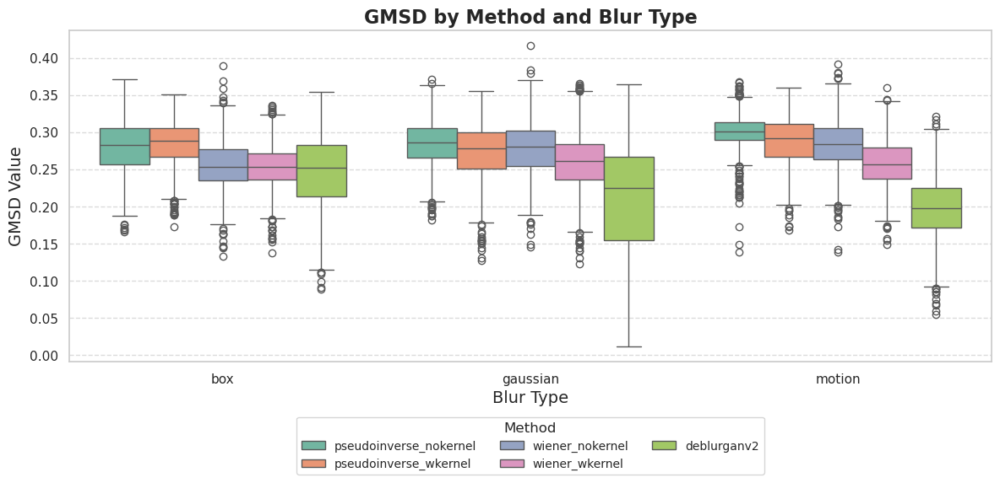

ANOVA Gaussian GMSD: F=412.86, p=1.934e-305
Descriptive statistics for GMSD:



count      mean       std       min  \
blur     method                                                        
box      deblurganv2             945.0  0.246702  0.047961  0.088188   
         pseudoinverse_nokernel  945.0  0.280592  0.033964  0.165641   
         pseudoinverse_wkernel   945.0  0.283664  0.029658  0.172723   
         wiener_nokernel         945.0  0.256072  0.033181  0.132841   
         wiener_wkernel          945.0  0.254166  0.030568  0.137076   
gaussian deblurganv2             945.0  0.208213  0.075455  0.011688   
         pseudoinverse_nokernel  945.0  0.283776  0.031794  0.181965   
         pseudoinverse_wkernel   945.0  0.273531  0.036369  0.126860   
         wiener_nokernel         945.0  0.278856  0.035171  0.145646   
         wiener_wkernel          945.0  0.260797  0.039422  0.122388   
motion   deblurganv2             945.0  0.195998  0.039951  0.054666   
         pseudoinverse_nokernel  945.0  0.300670  0.024277  0.138564   
         pseudoinverse_wkernel   945.0  0.286700  0.031355  0.167912   
         wiener_nokernel         945.0  0.283772  0.032785  0.138581   
         wiener_wkernel          945.0  0.259102  0.033523  0.149072   

                                      25%       50%       75%       max  
blur     method                                                          
box      deblurganv2             0.213969  0.252563  0.282378  0.354473  
         pseudoinverse_nokernel  0.256029  0.282713  0.305036  0.371573  
         pseudoinverse_wkernel   0.266913  0.288133  0.305665  0.351029  
         wiener_nokernel         0.234892  0.253677  0.276668  0.389490  
         wiener_wkernel          0.236433  0.253142  0.271626  0.336442  
gaussian deblurganv2             0.154598  0.224651  0.267345  0.364632  
         pseudoinverse_nokernel  0.265760  0.285572  0.305265  0.370736  
         pseudoinverse_wkernel   0.250852  0.278554  0.299372  0.355115  
         wiener_nokernel         0.254672  0.280915  0.302000  0.417039  
         wiener_wkernel          0.236685  0.261263  0.284016  0.365744  
motion   deblurganv2             0.171671  0.198081  0.225196  0.321087  
         pseudoinverse_nokernel  0.290024  0.300921  0.313213  0.367308  
         pseudoinverse_wkernel   0.266360  0.292137  0.311252  0.359355  
         wiener_nokernel         0.263911  0.284314  0.304840  0.391618  
         wiener_wkernel          0.237634  0.257061  0.279147  0.359745

In [5]:
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

sns.set_theme(style="whitegrid")

from common.config import METRIC_TYPES

for metric in METRIC_TYPES:
    # Melt the data for the current metric
    melted = []
    for method, df in dfs.items():
        for b in BLUR_TYPES:
            melted.append(df[[f'{metric}_{b}']].assign(method=method, blur=b, value=df[f'{metric}_{b}']))
    melted = pd.concat(melted)

    # Generate boxplot
    plt.figure(figsize=(12, 6))
    sns.set_theme(style="whitegrid")  # Set a nice theme
    sns.boxplot(x='blur', y='value', hue='method', data=melted, palette="Set2")
    plt.title(f'{metric.upper()} by Method and Blur Type', fontsize=16, fontweight='bold')
    plt.xlabel('Blur Type', fontsize=14)
    plt.ylabel(f'{metric.upper()} Value', fontsize=14)
    plt.legend(title='Method', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add grid lines
    plt.tight_layout()
    plt.show()

    # Perform ANOVA for Gaussian blur
    gauss_metric = [df[f'{metric}_gaussian'] for df in dfs.values()]
    f_stat, p_val = stats.f_oneway(*gauss_metric)
    print(f"ANOVA Gaussian {metric.upper()}: F={f_stat:.2f}, p={p_val:.3e}")

    # Compute descriptive statistics for each blur type and method
    descriptive_stats = melted.groupby(['blur', 'method'])['value'].describe()
    print(f"Descriptive statistics for {metric.upper()}:\n")
    display(descriptive_stats)

Aggregate Method Ranking (1 — Best):
pseudoinverse_nokernel    4.9
pseudoinverse_wkernel     4.1
wiener_nokernel           2.8
wiener_wkernel            2.2
deblurganv2               1.0
Name: aggregate_rank, dtype: float64


/tmp/ipykernel_5419/919405841.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


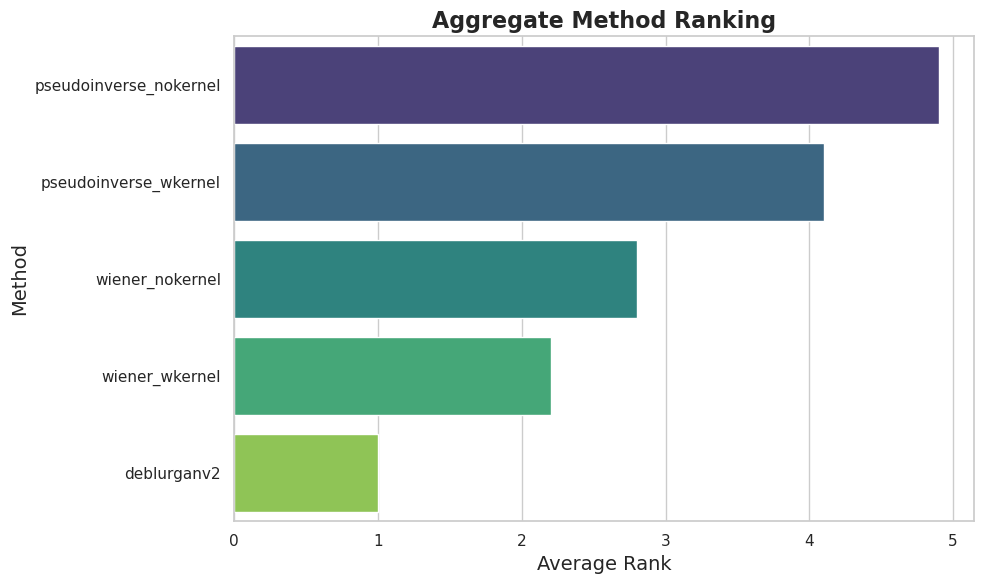

In [6]:
import pandas as pd
import numpy as np
from scipy.stats import rankdata
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Collect mean metric values for each method
mean_metrics = {}
for method, df in dfs.items():
    vals = {m: df[m].mean() for m in METRIC_TYPES}
    mean_metrics[method] = vals
mean_df = pd.DataFrame(mean_metrics).T

# 2. Convert metrics to ranks: rank 1 — best
ranks = pd.DataFrame(index=mean_df.index, columns=mean_df.columns, dtype=float)
for m in METRIC_TYPES:
    ascending = (m in ['lpips', 'gmsd', 'proctime'])  # For these metrics, lower is better
    if ascending:
        ranks[m] = rankdata(mean_df[m], method='average')
    else:
        ranks[m] = rankdata(-mean_df[m], method='average')

# 3. Compute aggregate rank and sort
ranks['aggregate_rank'] = ranks.mean(axis=1)
final_ranking = ranks['aggregate_rank'].sort_values(ascending=False)

# Display aggregate ranking
print("Aggregate Method Ranking (1 — Best):")
print(final_ranking)

# 4. Visualize the ranking
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
sns.barplot(
    x=final_ranking.values, 
    y=final_ranking.index, 
    palette="viridis"
)
plt.title('Aggregate Method Ranking', fontsize=16, fontweight='bold')
plt.xlabel('Average Rank', fontsize=14)
plt.ylabel('Method', fontsize=14)
plt.tight_layout()
plt.show()



=== Parameter Analysis: motion_length ===
Dependent Variable: SSIM Motion (DeblurGANv2)
Independent Variable: motion_length
Number of Observations: 945.0
Coefficients:
const            0.766939
motion_length   -0.006702
dtype: float64
R²: 0.1360
Adjusted R²: 0.1351
F-statistic: 148.4191
P-value (F-statistic): 8.2072e-32
Standard Errors:
const            0.010544
motion_length    0.000550
dtype: float64
Confidence Intervals:
                      0         1
const          0.746246  0.787632
motion_length -0.007782 -0.005622


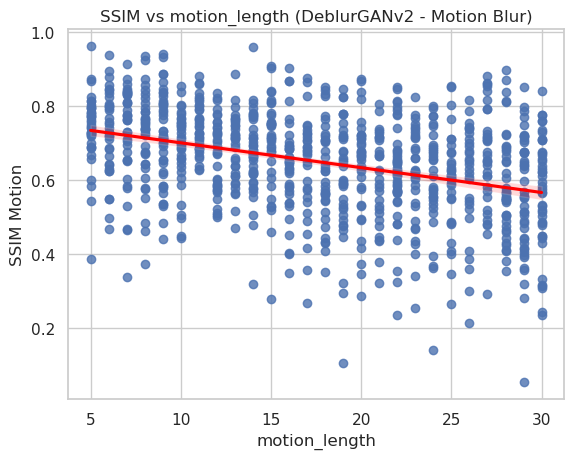


=== Parameter Analysis: motion_angle ===
Dependent Variable: SSIM Motion (DeblurGANv2)
Independent Variable: motion_angle
Number of Observations: 945.0
Coefficients:
const           0.641240
motion_angle    0.000043
dtype: float64
R²: 0.0010
Adjusted R²: -0.0000
F-statistic: 0.9673
P-value (F-statistic): 3.2561e-01
Standard Errors:
const           0.009174
motion_angle    0.000044
dtype: float64
Confidence Intervals:
                     0         1
const         0.623236  0.659244
motion_angle -0.000043  0.000128


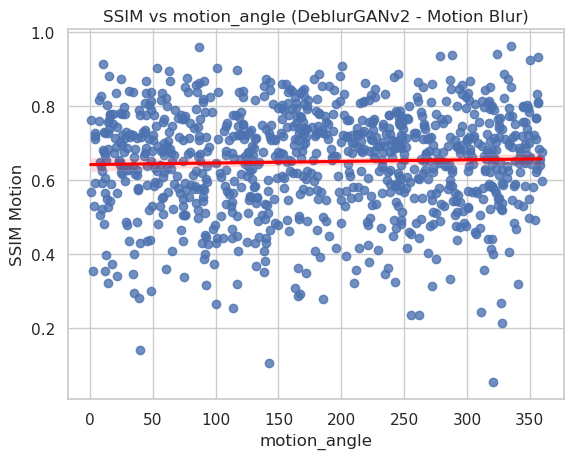

In [7]:
# 3. Чутливість методів до параметрів розмиття (лінійна регресія)
import statsmodels.api as sm

# Filter data for DeblurGANv2 and motion blur
filtered_df = dfs['deblurganv2']

for param, col in [('motion_length', 'motion_length'), ('motion_angle', 'motion_angle')]:
    if col in filtered_df.columns:
        X = sm.add_constant(filtered_df[col])
        y = filtered_df['ssim_motion']  # SSIM for DeblurGANv2 with motion blur
        model = sm.OLS(y, X).fit()
        
        # Detailed textual output
        print(f"\n=== Parameter Analysis: {param} ===")
        print(f"Dependent Variable: SSIM Motion (DeblurGANv2)")
        print(f"Independent Variable: {param}")
        print(f"Number of Observations: {model.nobs}")
        print(f"Coefficients:\n{model.params}")
        print(f"R²: {model.rsquared:.4f}")
        print(f"Adjusted R²: {model.rsquared_adj:.4f}")
        print(f"F-statistic: {model.fvalue:.4f}")
        print(f"P-value (F-statistic): {model.f_pvalue:.4e}")
        print(f"Standard Errors:\n{model.bse}")
        print(f"Confidence Intervals:\n{model.conf_int()}")
        
        # Plot regression
        sns.regplot(x=filtered_df[col], y=y, line_kws={'color': 'red'})
        plt.title(f"SSIM vs {param} (DeblurGANv2 - Motion Blur)")
        plt.xlabel(param)
        plt.ylabel('SSIM Motion')
        plt.show()


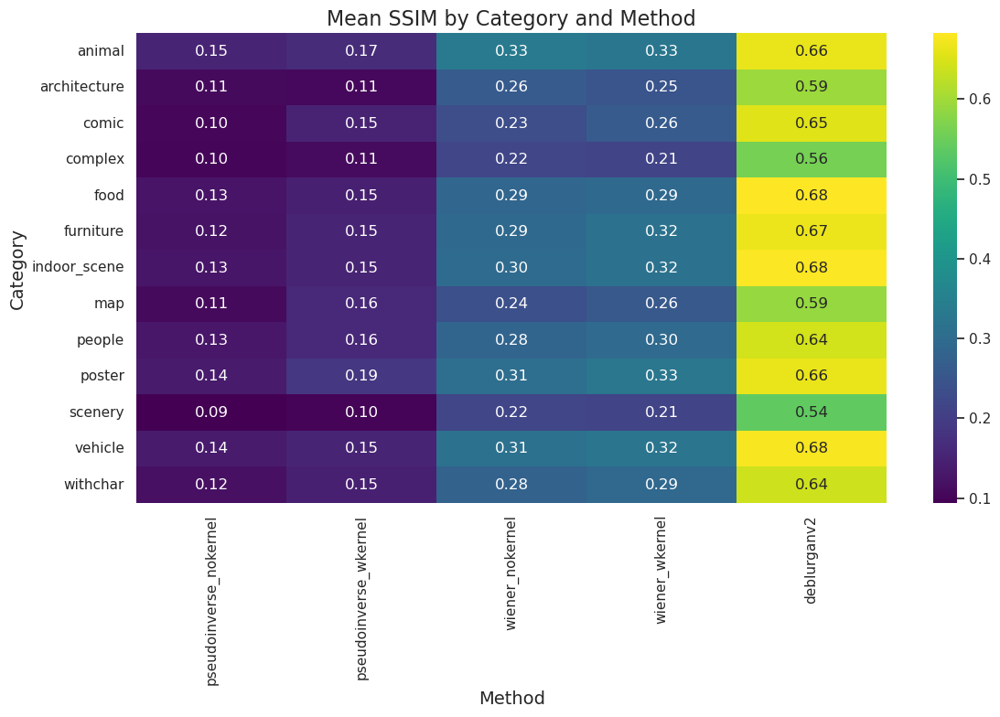

Mean SSIM by Category and Method:


,pseudoinverse_nokernel,pseudoinverse_wkernel,wiener_nokernel,wiener_wkernel,deblurganv2
category,,,,,
animal,0.153112,0.167333,0.333255,0.326096,0.662772
architecture,0.109376,0.107994,0.261605,0.246520,0.594615
comic,0.104848,0.150209,0.234080,0.260446,0.654892
complex,0.101329,0.110707,0.217769,0.211765,0.559039
food,0.126378,0.146697,0.286081,0.293762,0.682503
furniture,0.123074,0.152530,0.292268,0.316706,0.665993
indoor_scene,0.127081,0.152602,0.297328,0.316773,0.678748
map,0.109571,0.159894,0.236946,0.257272,0.588786
people,0.129191,0.160508,0.284013,0.296422,0.641671


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# 4. Узагальнення методів за категоріями контенту
cat_summary = {method: df.groupby('category')['ssim'].mean() for method, df in dfs.items()}
cat_df = pd.DataFrame(cat_summary)

# Create heatmap using seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(cat_df, annot=True, cmap='viridis', fmt=".2f")
plt.title('Mean SSIM by Category and Method', fontsize=16)
plt.xlabel('Method', fontsize=14)
plt.ylabel('Category', fontsize=14)
plt.tight_layout()
plt.show()

# Display textual information
print("Mean SSIM by Category and Method:")
display(cat_df)


pseudoinverse_nokernel: Selected features: ['rms_contrast', 'canny_edge_density', 'gaussian_sigma']
pseudoinverse_nokernel:
  Selected feature: rms_contrast         | coef: -0.2797
  Selected feature: canny_edge_density   | coef: -0.3592
  Selected feature: gaussian_sigma       | coef: -0.0041

Mean Squared Error (MSE) on Test Data: 0.0034
R-squared (R2) on Test Data: 0.1221



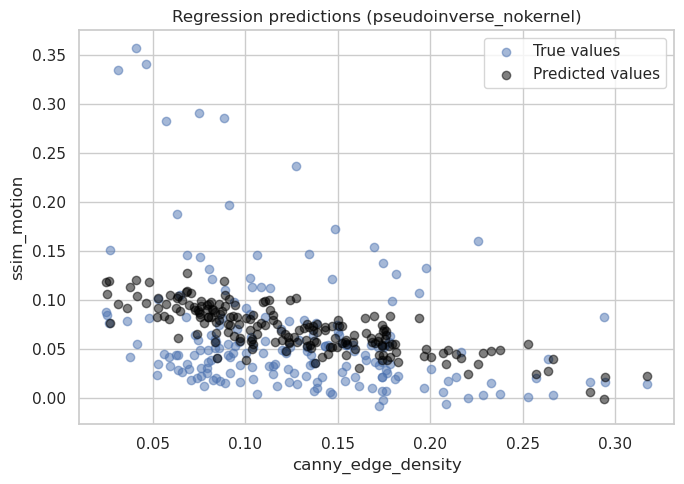

pseudoinverse_wkernel: Selected features: ['rms_contrast', 'canny_edge_density', 'aspect_ratio']
pseudoinverse_wkernel:
  Selected feature: rms_contrast         | coef: -0.2511
  Selected feature: canny_edge_density   | coef: -0.4045
  Selected feature: aspect_ratio         | coef: -0.0019

Mean Squared Error (MSE) on Test Data: 0.0109
R-squared (R2) on Test Data: 0.0862



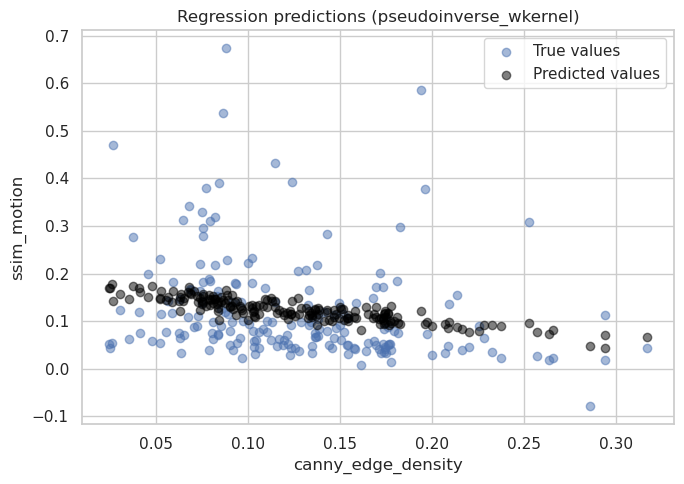

wiener_nokernel: Selected features: ['rms_contrast', 'canny_edge_density', 'gaussian_sigma']
wiener_nokernel:
  Selected feature: rms_contrast         | coef: -0.4438
  Selected feature: canny_edge_density   | coef: -1.0298
  Selected feature: gaussian_sigma       | coef: -0.0071

Mean Squared Error (MSE) on Test Data: 0.0105
R-squared (R2) on Test Data: 0.3049



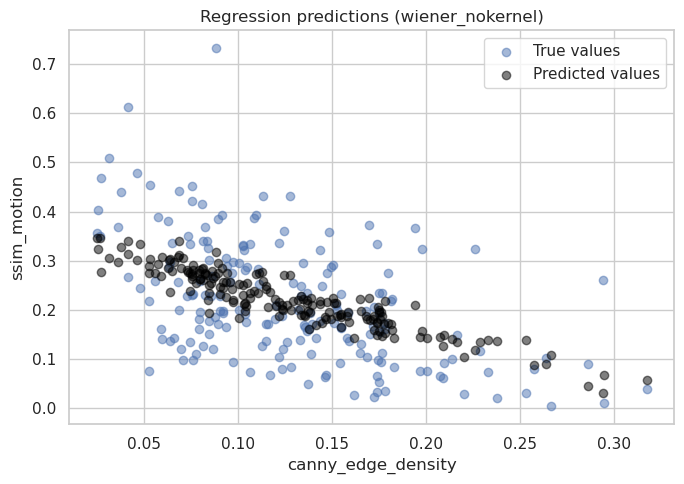

wiener_wkernel: Selected features: ['rms_contrast', 'canny_edge_density', 'motion_length']
wiener_wkernel:
  Selected feature: rms_contrast         | coef: -0.4376
  Selected feature: canny_edge_density   | coef: -1.0615
  Selected feature: motion_length        | coef: -0.0066

Mean Squared Error (MSE) on Test Data: 0.0106
R-squared (R2) on Test Data: 0.4163



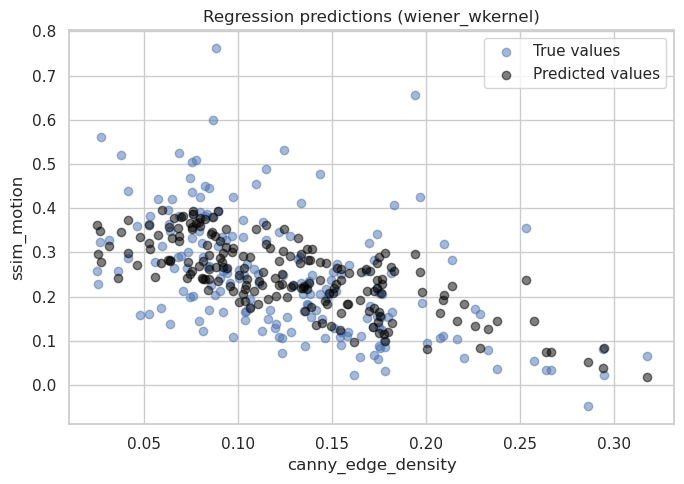

deblurganv2: Selected features: ['rms_contrast', 'canny_edge_density', 'aspect_ratio']
deblurganv2:
  Selected feature: rms_contrast         | coef: 0.0231
  Selected feature: canny_edge_density   | coef: -1.2429
  Selected feature: aspect_ratio         | coef: 0.0338

Mean Squared Error (MSE) on Test Data: 0.0109
R-squared (R2) on Test Data: 0.3955



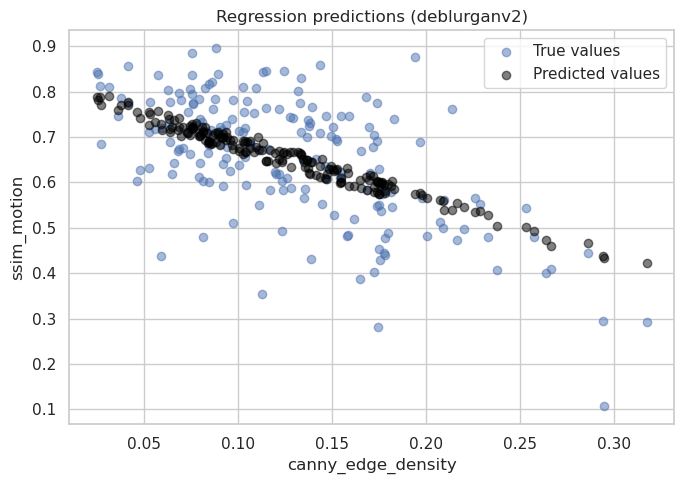

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

from common.config import FIGURES_DIR

is_save = True  # Use Python boolean

# Define candidate features
features = ['rms_contrast', 'canny_edge_density', 'aspect_ratio', 
            'sobel_edge_strength', 'motion_length', 'gaussian_sigma']

r2_values = []
for method, df in dfs.items():
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
    X_train = train_df[features]
    y_train = train_df['ssim_motion']

    lr = LinearRegression()
    selector = RFE(lr, n_features_to_select=3)
    selector.fit(X_train, y_train)

    selected_features = [features[i] for i in range(len(features)) if selector.support_[i]]
    print(f"{method}: Selected features: {selected_features}")

    coefs = selector.estimator_.coef_
    print(f"{method}:")
    for feat, coef in zip(selected_features, coefs):
        print(f"  Selected feature: {feat:20s} | coef: {coef:.4f}")
    print()

    # Get the most impactful feature (largest absolute coefficient)
    abs_coefs = np.abs(coefs)
    most_impactful_idx = abs_coefs.argmax()
    most_impactful_feature = selected_features[most_impactful_idx]

    X_test = test_df[features]
    y_test = test_df['ssim_motion']
    y_pred = selector.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    r2_values.append(r2)

    print(f"Mean Squared Error (MSE) on Test Data: {mse:.4f}")
    print(f"R-squared (R2) on Test Data: {r2:.4f}\n")

    plt.figure(figsize=(7, 5))
    plt.scatter(X_test[most_impactful_feature], y_test, alpha=0.5, label='True values')
    plt.scatter(X_test[most_impactful_feature], y_pred, c='black', alpha=0.5, label='Predicted values')
    plt.title(f'Regression predictions ({method})')
    plt.xlabel(most_impactful_feature)
    plt.ylabel('ssim_motion')
    plt.legend()
    plt.tight_layout()
    if is_save:
        fig_dir = FIGURES_DIR
        fig_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(fig_dir / f"regression_preds_{method}.png")
    plt.show()


In [10]:
from scipy.stats import ttest_rel

# Perform paired t-test for SSIM between Wiener with kernel and without kernel
w1 = dfs['wiener_wkernel']['ssim']  # SSIM values for Wiener with kernel
w0 = dfs['wiener_nokernel']['ssim']  # SSIM values for Wiener without kernel

# Calculate test statistic and p-value
stat, p = ttest_rel(w1, w0)

# Display results with clear explanation
print("Paired t-test results for SSIM (Wiener with kernel vs without kernel):")
print(f"Test statistic (t): {stat:.2f}")
print(f"P-value: {p:.3e}")
print("Interpretation:")
print("- A small p-value indicates a significant difference between the two methods.")
print("- If p < 0.05, we reject the null hypothesis and conclude that Wiener with kernel performs better.")


Paired t-test results for SSIM (Wiener with kernel vs without kernel):
Test statistic (t): 3.77
P-value: 1.750e-04
Interpretation:
- A small p-value indicates a significant difference between the two methods.
- If p < 0.05, we reject the null hypothesis and conclude that Wiener with kernel performs better.


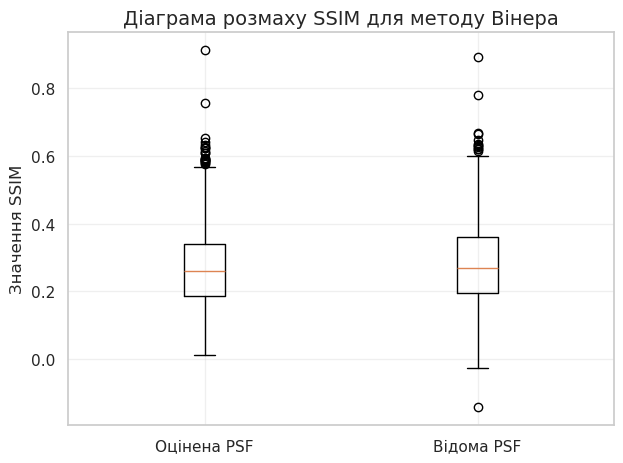

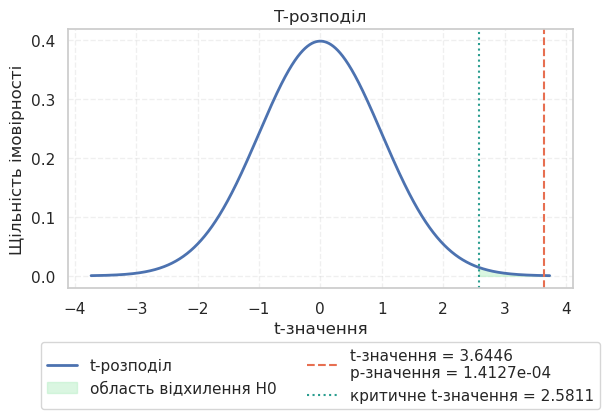

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import t

# Extract the data from the t-test
w1 = dfs['wiener_wkernel']['ssim']  # SSIM values for Wiener with kernel
w0 = dfs['wiener_nokernel']['ssim']  # SSIM values for Wiener without kernel
D = w1 - w0  # Differences

# Calculate key statistics
mean_diff = D.mean()
std_diff = D.std()
n = len(D)
se_diff = std_diff / np.sqrt(n)
df = n - 1

# Calculate 99% confidence interval
confidence_level = 0.99
alpha = 1 - confidence_level
t_critical = t.ppf(1 - alpha/2, df)
margin_error = t_critical * se_diff
ci_lower = mean_diff - margin_error
ci_upper = mean_diff + margin_error

# Calculate t-statistic and p-value
t_stat = mean_diff / se_diff
p_value = (1 - t.cdf(t_stat, df))
p_value_one_tailed = p_value

# 3. Box plot of both distributions (separate figure)
plt.figure()
sns.set_theme(style="whitegrid")
data = [w0, w1]
plt.boxplot(data, tick_labels=['Оцінена PSF', 'Відома PSF'])
plt.title('Діаграма розмаху SSIM для методу Вінера', fontsize=14)
plt.ylabel('Значення SSIM', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. T-distribution with test statistic (separate figure)
plt.figure()
x = np.linspace(t.ppf(0.0001, df), t.ppf(0.9999, df), 2000)
plt.plot(x, t.pdf(x, df), 'b-', lw=2, label='t-розподіл')
plt.fill_between(x, t.pdf(x, df), where=(x >= t_critical), color='#b7efc5', alpha=0.5,
                 label='область відхилення H0')
plt.axvline(t_stat, color='#e76f51', linestyle='--',
            label=f't-значення = {t_stat:.4f}\np-значення = {p_value_one_tailed:.4e}')
plt.axvline(t_critical, color='#2a9d8f', linestyle=':',
            label=f'критичне t-значення = {t_critical:.4f}')
plt.title('T-розподіл')
plt.xlabel('t-значення', fontsize=12)
plt.ylabel('Щільність імовірності', fontsize=12)
plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


In [11]:
# 8. Оцінка узагальнюваності: k-Fold CV для регресійної моделі
from sklearn.model_selection import KFold, cross_val_score

# Використовуємо дані для методу 'wiener_wkernel'
X = dfs['wiener_wkernel'][features]  # Ознаки: контраст, щільність країв, довжина розмиття тощо
y = dfs['wiener_wkernel']['ssim']  # Цільова змінна: SSIM

# Налаштування крос-валідації
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Оцінка моделі лінійної регресії
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2')

# Виведення результатів
print("Результати крос-валідації (R2):", scores)
print("Середнє значення R2:", scores.mean())


Результати крос-валідації (R2): [0.67546561 0.61960481 0.56279858 0.61059167 0.60317142]
Середнє значення R2: 0.6143264186638815


Key: 000000585
SSIM Motion: 0.1070
LPIPS Motion: 0.4581
URL: http://static.showit.co/1600/vMSyA_qqQP6V9vfQcx5Z4Q/59593/pickychicken8062-gold-08-glittersmall.jpg
Category: complex
Image Dimensions: 1200x1200
Processing Time (Motion): 0.1574 seconds
--------------------------------------------------


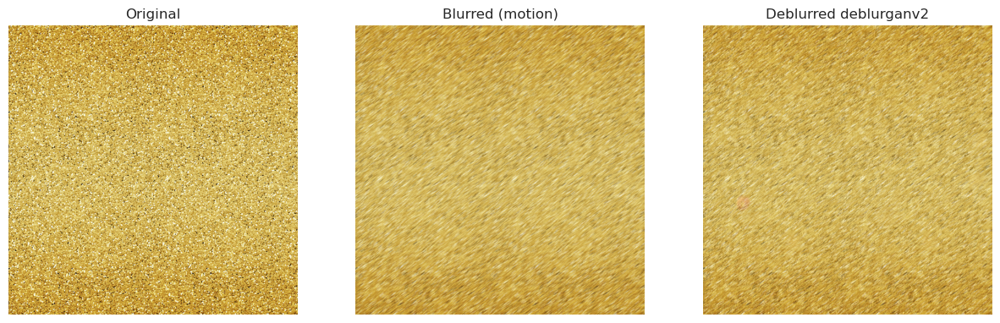

Key: 000000657
SSIM Motion: 0.4008
LPIPS Motion: 0.3583
URL: http://img0.etsystatic.com/007/0/6623273/il_170x135.384922892_41us.jpg
Category: food
Image Dimensions: 170x135
Processing Time (Motion): 0.0435 seconds
--------------------------------------------------


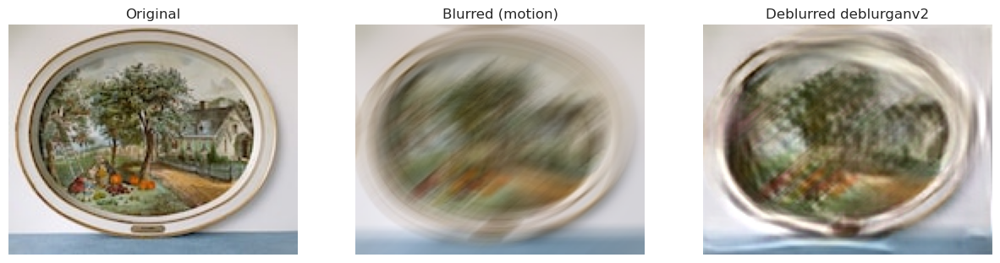

Key: 000000556
SSIM Motion: 0.3925
LPIPS Motion: 0.3548
URL: https://cdn.shopify.com/s/files/1/1582/7955/products/image_db0918a6-163d-4e28-9989-a671c638f4da_1920x.jpg?v=1571439351
Category: complex
Image Dimensions: 1354x2048
Processing Time (Motion): 0.2945 seconds
--------------------------------------------------


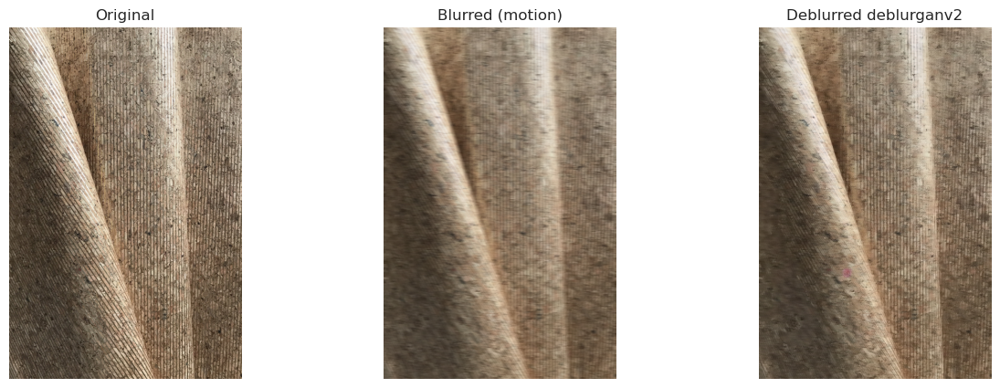

In [12]:
from common.img_output import show_comparison

# Аналіз невдач: вибір найгірших випадків
# Вибираємо три найгірші випадки за метрикою lpips_motion для методу DeblurGANv2
worst = dfs[df_name].nlargest(3, 'lpips_motion')

# Виводимо ключові характеристики кожного з найгірших випадків
for idx, row in worst.iterrows():
    print(f"Key: {row['key']}")
    print(f"SSIM Motion: {row['ssim_motion']:.4f}")
    print(f"LPIPS Motion: {row['lpips_motion']:.4f}")
    print(f"URL: {row['url']}")
    print(f"Category: {row['category']}")
    print(f"Image Dimensions: {int(row['width'])}x{int(row['height'])}")
    print(f"Processing Time (Motion): {row['proctime_motion']:.4f} seconds")
    print("-" * 50)
    
    # Візуалізація порівняння для кожного випадку
    show_comparison(row["key"], df_name, ["motion"])


## 5. Descriptive statistics and Data exploration


In the following cells, we present descriptive statistics for the image dataset and the deblurring metrics obtained with DeblurGANv2. We display summary statistics for the original image features and for the main quality metrics (e.g., SSIM, LPIPS) computed on motion-blurred images. This provides an overview of the data distribution and helps identify trends or anomalies before proceeding with further statistical analysis.


In [13]:
print("Image characteristics")
display(original_df.describe())

print("Metrics for the approach (deblurganv2)")
display(dfs["deblurganv2"][[f"{x}_motion" for x in METRIC_TYPES]].describe())

Image characteristics


,width,height,aspect_ratio,size,rms_contrast,sobel_edge_strength,canny_edge_density,box_size,gaussian_sigma,gaussian_size,motion_length,motion_angle
count,950.000000,950.000000,950.000000,9.500000e+02,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,1556.865263,1361.677895,1.215505,3.510588e+06,0.241307,63.759947,0.128991,10.117895,2.199617,13.461053,17.590526,183.191937
std,461.015906,434.723050,0.383402,1.992244e+06,0.054723,25.274638,0.057644,3.151395,0.995533,5.549477,7.629577,103.763953
min,170.000000,117.000000,0.463392,7.694000e+03,0.060424,8.266673,0.000000,5.000000,0.515940,5.000000,5.000000,0.618597
25%,1223.000000,1080.000000,0.800500,2.274401e+06,0.204291,45.575302,0.088474,7.000000,1.348071,9.000000,11.000000,91.414728
50%,1500.000000,1280.000000,1.333333,3.223864e+06,0.239974,61.044392,0.123753,10.000000,2.155779,13.000000,18.000000,181.171951
75%,1920.000000,1600.000000,1.500000,4.179430e+06,0.277998,78.197440,0.162452,13.000000,3.062990,19.000000,24.000000,272.798978
max,4000.000000,4066.000000,3.200000,1.768750e+07,0.430649,203.722492,0.373182,15.000000,3.998513,21.000000,30.000000,359.313659


Metrics for the approach (deblurganv2)


,proctime_motion,ssim_motion,psnr_motion,lpips_motion,gmsd_motion
count,945.000000,945.000000,945.000000,945.000000,945.000000
mean,0.236605,0.649095,21.902328,0.038539,0.195998
std,0.143114,0.138746,3.233108,0.046739,0.039951
min,0.043471,0.053819,9.067159,0.000395,0.054666
25%,0.176777,0.566989,19.648233,0.008165,0.171671
50%,0.214118,0.669053,21.852450,0.026116,0.198081
75%,0.269920,0.746460,23.904904,0.051795,0.225196
max,2.181084,0.960551,34.828347,0.458100,0.321087


Noticing that for the DeblurGANv2 metrics, the maximum value of `proctime_motion` is 23.68 while the 75th percentile is only 0.27, we decided to analyze the images with the highest processing times.  
We observed a clear correlation between image dimensions (height, width and thus size) and processing time: higher-resolution images require more processing time. Therefore, we removed the outliers with the highest processing times and visualized pairplot matrices to illustrate the relationship between processing time and image size characteristics.


In [14]:
top_proctime_df = dfs["deblurganv2"].nlargest(5, "proctime")[["key", "proctime", "proctime_box", "proctime_gaussian", "proctime_motion", "size", "width", "height"]]

top_proctime_df

,key,proctime,proctime_box,proctime_gaussian,proctime_motion,size,width,height
377,000001207,2.284155,2.384044,2.287336,2.181084,15721443.0,2399.0,3036.0
537,000001222,1.613782,1.708156,1.464757,1.668434,6531868.0,2890.0,2410.0
837,000000821,1.375062,1.380599,1.396174,1.348415,12412303.0,3000.0,2254.0
712,000000842,1.344908,1.396917,1.316039,1.321767,8472127.0,3500.0,2100.0
101,000001165,1.098550,1.177681,1.046731,1.071238,9060934.0,3050.0,2308.0


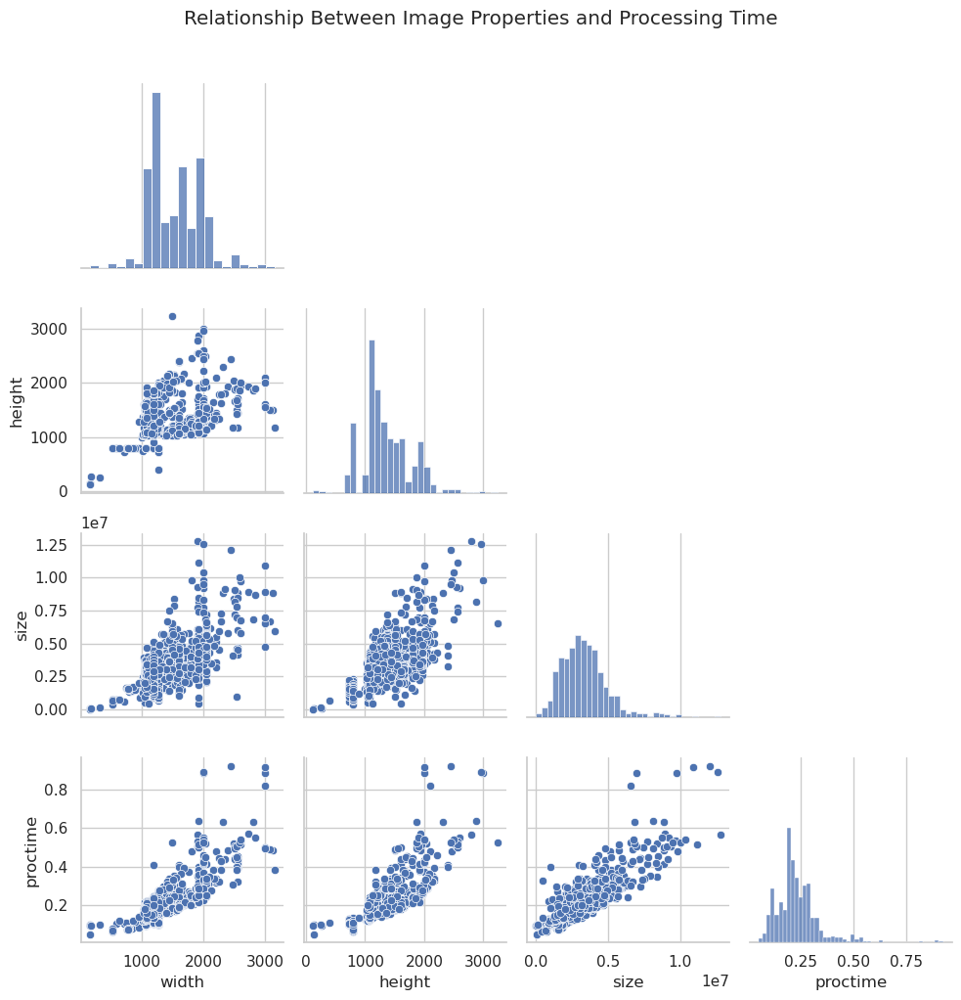

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_cols = ['width', 'height', 'size', 'proctime']

outlier_idxs = top_proctime_df.index

for df_name in dfs.keys():
    dfs[df_name] = dfs[df_name].drop(outlier_idxs)

g = sns.pairplot(dfs['deblurganv2'][plot_cols], diag_kind='hist', corner=True)
plt.suptitle('Relationship Between Image Properties and Processing Time', y=1.02)
plt.tight_layout()
plt.show()

We explore the distribution and relationships of the metrics (such as SSIM, LPIPS, GMSD, PSNR and processing time) for the DeblurGANv2 method. We visualize the metrics using pairplot matrices to identify potential correlations and trends. This step provides an overview of the metric distributions and their interdependencies, serving as a foundation for further statistical analysis and hypothesis testing.


In [16]:
from common.config import METRIC_TYPES, BLUR_PARAM_RANGES

save_to_csv = True
csv_dir = "correlation_matrices_csv"
import os

os.makedirs(csv_dir, exist_ok=True)
csv_dict = {}

for method, df in dfs.items():
    all_corrs = []
    all_param_names = []
    for blur_type, params in BLUR_PARAM_RANGES.items():
        # Select metric columns
        metric_cols = [f"{metric}_{blur_type}" for metric in METRIC_TYPES if f"{metric}_{blur_type}" in df.columns]
        # Add blur-specific parameter columns
        param_cols = [f"{blur_type}_{param}" for param in params.keys() if f"{blur_type}_{param}" in df.columns]
        # Combine metric and parameter columns
        cols = metric_cols + param_cols
        data = df[cols]
        # Compute correlation matrix
        corr = data.corr()
        # Only keep param_cols as rows, metric_cols as columns
        corr_sub = corr.loc[param_cols, metric_cols]
        # Rename columns to metric names only (e.g. ssim_box -> ssim)
        corr_sub.columns = [c.split("_")[0] for c in corr_sub.columns]
        # Store for concatenation
        all_corrs.append(corr_sub)
        # Store param names with blur type for index
        all_param_names.extend([f"{blur_type}_{p}" for p in params.keys() if f"{blur_type}_{p}" in df.columns])
    # Concatenate all param rows for this method
    combined_corr = pd.concat(all_corrs)
    combined_corr.index = all_param_names
    csv_dict[method] = combined_corr

    # Display as before
    print(f"Combined correlation matrix for {method.upper()}:")
    display(combined_corr)

if save_to_csv:
    for method, corr_df in csv_dict.items():
        corr_df.to_csv(os.path.join(csv_dir, f"{method}.csv"))
    print(f"Correlation matrices saved to directory: {csv_dir}")


Combined correlation matrix for PSEUDOINVERSE_NOKERNEL:


,proctime,ssim,psnr,lpips,gmsd
box_size,-0.012405,0.520460,0.484627,0.283638,-0.298212
gaussian_size,-0.017637,0.711264,0.780189,-0.542213,-0.404740
gaussian_sigma,-0.022342,0.704142,0.768762,-0.517949,-0.392361
motion_length,-0.083317,0.201096,0.316121,0.111370,-0.076750
motion_angle,0.000658,-0.025924,-0.011620,-0.018544,0.033668


Combined correlation matrix for PSEUDOINVERSE_WKERNEL:


,proctime,ssim,psnr,lpips,gmsd
box_size,-0.012405,-0.332757,-0.354649,0.634375,0.179521
gaussian_size,-0.017637,-0.397761,-0.428332,0.536640,0.472954
gaussian_sigma,-0.022342,-0.403771,-0.424786,0.548034,0.466138
motion_length,-0.083317,-0.439743,-0.524214,0.648787,0.257719
motion_angle,0.000658,-0.019917,-0.026975,-0.016013,0.013573


Combined correlation matrix for WIENER_NOKERNEL:


...

Combined correlation matrix for WIENER_WKERNEL:


,proctime,ssim,psnr,lpips,gmsd
box_size,-0.008927,-0.260180,-0.259005,0.602651,0.215211
gaussian_size,-0.017348,-0.180559,-0.328273,0.572734,0.403498
gaussian_sigma,-0.021860,-0.181538,-0.322181,0.573102,0.398960
motion_length,-0.083091,-0.380386,-0.439226,0.710002,0.241317
motion_angle,-0.003512,-0.027126,-0.037910,-0.015892,0.048646


Combined correlation matrix for DEBLURGANV2:


,proctime,ssim,psnr,lpips,gmsd
box_size,-0.026779,-0.399654,-0.249227,0.608640,0.481748
gaussian_size,-0.008992,-0.708082,-0.568799,0.636074,0.801076
gaussian_sigma,-0.014830,-0.707664,-0.569646,0.653930,0.797443
motion_length,-0.071298,-0.371374,-0.219563,0.518113,0.402818
motion_angle,0.025472,0.032248,0.003956,-0.025621,-0.014529


Correlation matrices saved to directory: correlation_matrices_csv


In [17]:
from common.deblurrers import PseudoInverseDeblurrer
from common.config import TEST_DEBLURRED_OFFICIAL_DIR, IDPA_DATASET, PSEUDOINVERSE_WKERNEL_DATASET

pseudo_deblurrer = PseudoInverseDeblurrer()

# w_kernel generation
gen_dataset(
    deblurrer=pseudo_deblurrer,
    output_path=TEST_DEBLURRED_OFFICIAL_DIR / f"{pseudo_deblurrer.get_name()}_wkernel",
    deblurrer_dataset_path=PSEUDOINVERSE_WKERNEL_DATASET,
    kernel_dataset_path=IDPA_DATASET,
)

ModuleNotFoundError: No module named 'albumentations'

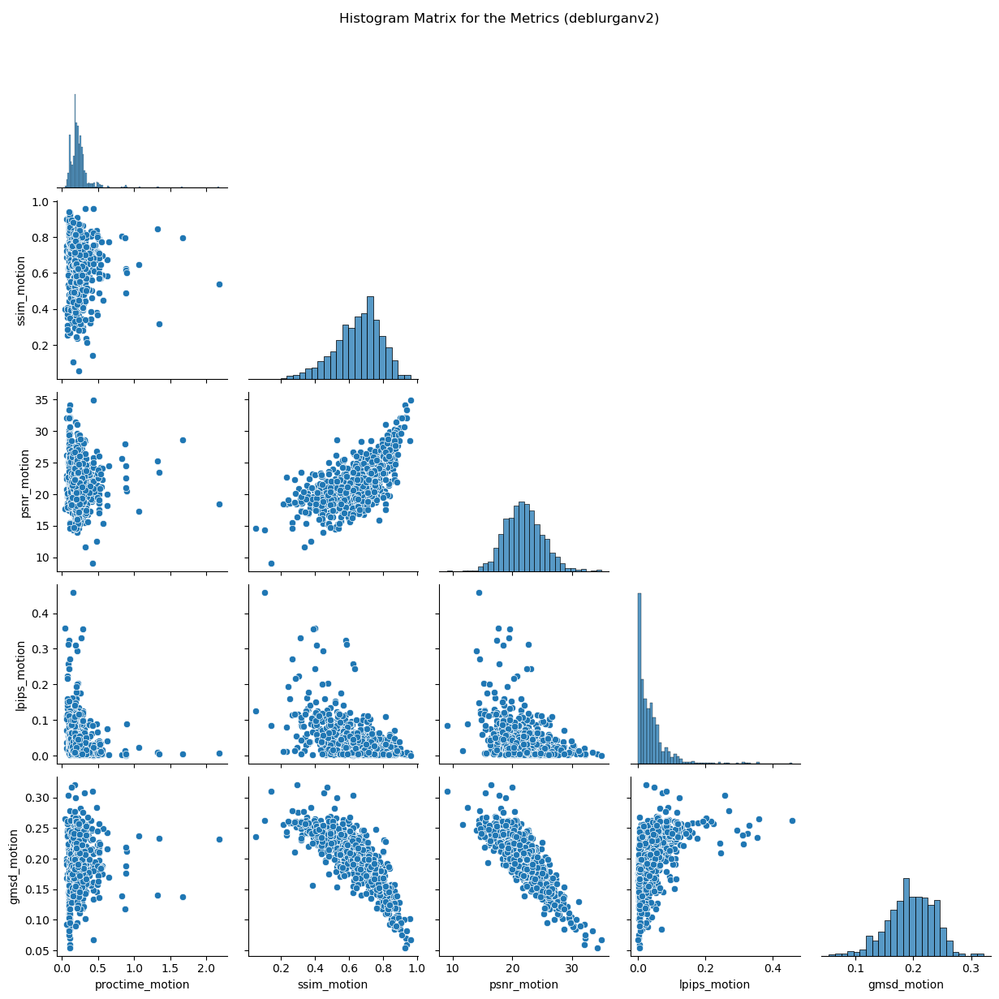

In [ ]:
metric_cols = [f'{metric}_motion' for metric in METRIC_TYPES if f'{metric}' in dfs['deblurganv2'].columns]
plot_df_wk = dfs['deblurganv2'][metric_cols].copy()

sns.pairplot(plot_df_wk, diag_kind='hist', corner=True)
plt.suptitle('Histogram Matrix for the Metrics (deblurganv2)')
plt.show()

To confirm our assumptions about the correlation of the metrics we compute a correlation heat map for each metric across all methods. The correlation is computed using the Pearson coefficient.

The Pearson correlation coefficient, denoted as $\rho$ for the population and $r$ for the sample, measures the linear relationship between two variables $X$ and $Y$. It is calculated as:

$$
\rho = \frac{\mathrm{Cov}(X, Y)}{\sigma_X \sigma_Y}
$$

where $\mathrm{Cov}(X, Y)$ is the covariance between $X$ and $Y$, and $\sigma_X$, $\sigma_Y$ are the standard deviations of $X$ and $Y$, respectively. The value of $r$ ranges from $-1$ (perfect negative linear correlation) to $+1$ (perfect positive linear correlation), with $0$ indicating no linear correlation.


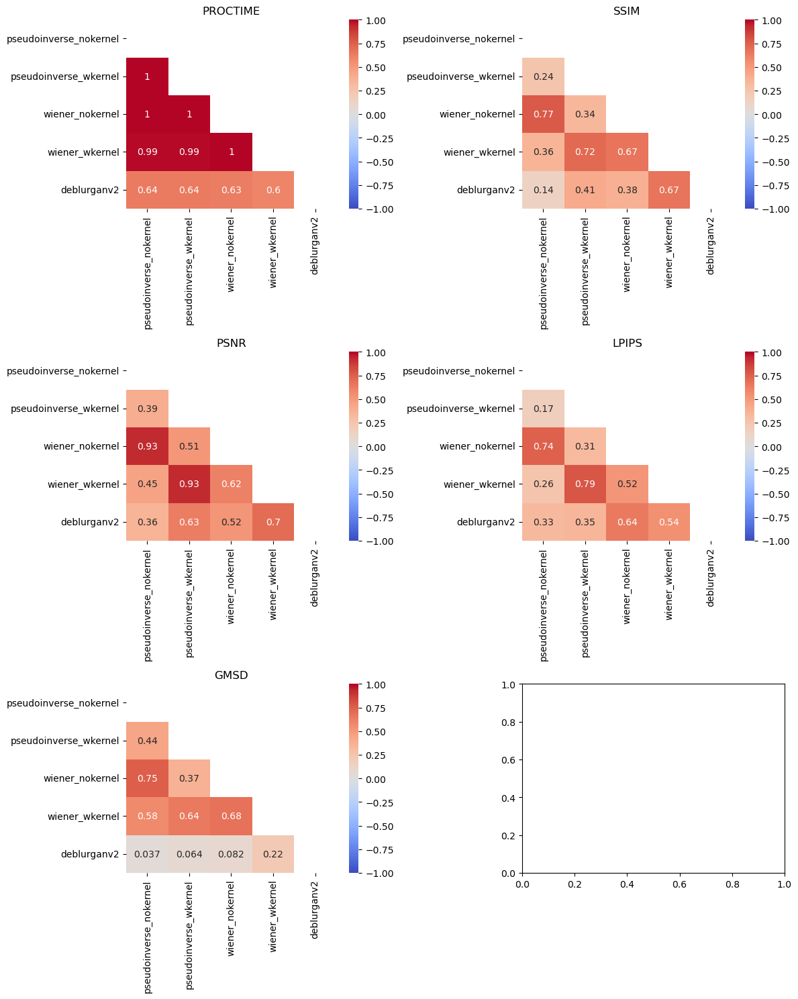

In [ ]:
n_metrics = len(METRIC_TYPES)
n_cols = 2
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows))
axes = axes.flatten()

for i, metric in enumerate(METRIC_TYPES):
    data = pd.DataFrame({
        method: df[metric] for method, df in dfs.items()
    })
    corr = data.corr()**2
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, mask=mask, ax=axes[i])
    axes[i].set_title(metric.upper())

plt.tight_layout()
plt.show()

We generate boxplots for each metric across all deblurring methods. This visualization allows for a direct comparison of the distribution and variability of each metric among the different approaches. By examining these boxplots, we can identify which methods tend to perform better or worse according to each metric, and observe the presence of outliers or differences in metric variability.

As shown by the boxplots, DeblurGANv2 consistently outperforms the two classical methods across all metrics:

- It is the fastest method in terms of processing time (`proctime`).
- For `ssim` and `psnr`, DeblurGANv2 achieves the highest values (higher is better).
- For `lpips` and `gmsd`, it obtains the lowest values (lower is better).

Additionally, for both classical methods, results are slightly better when the blur kernel is known compared to when it is not.


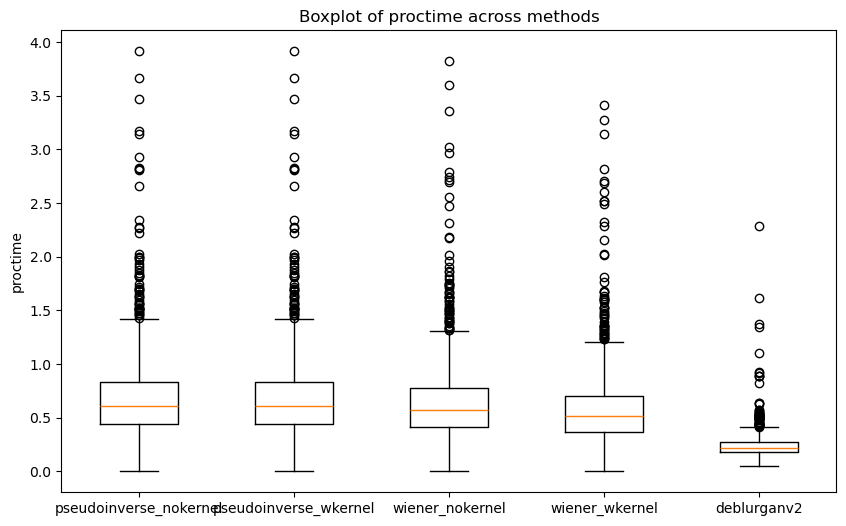

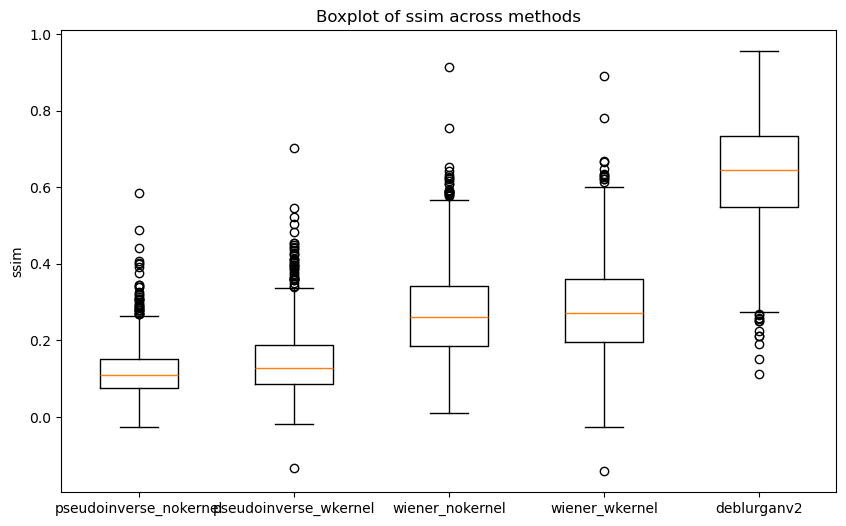

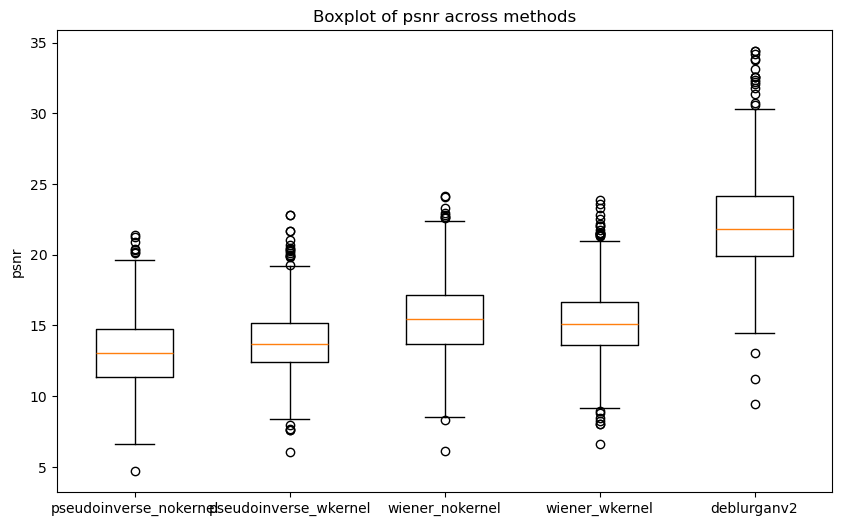

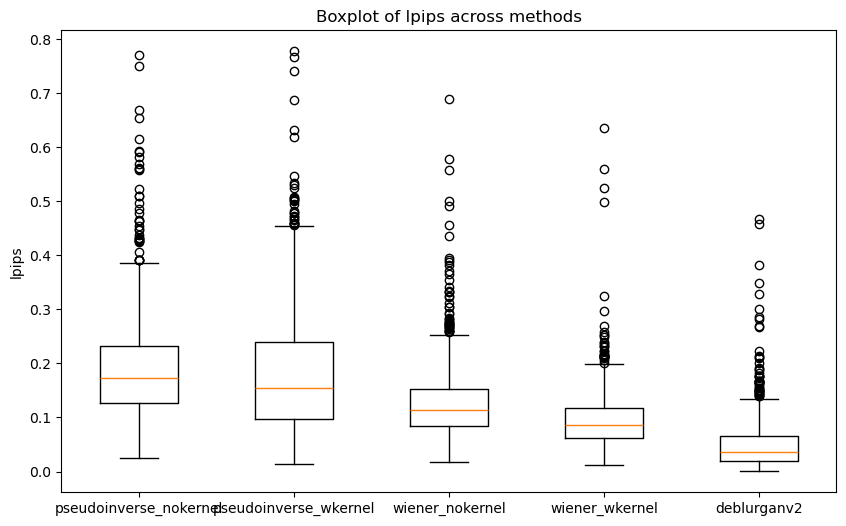

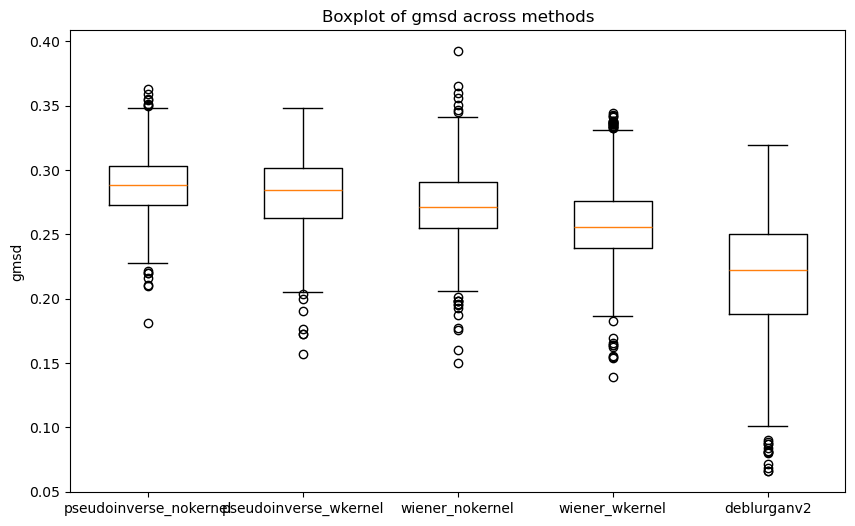

In [ ]:
for metric in METRIC_TYPES:
    plt.figure(figsize=(10, 6))
    data = [df[metric] for df in dfs.values()]
    plt.boxplot(data, tick_labels=dfs.keys())
    plt.title(f'Boxplot of {metric} across methods')
    plt.ylabel(metric)
    plt.show()

We confirm the assumptions about performance by comparing the means of each metric.


In [ ]:
display(pd.DataFrame({
    method: [df[metric].mean() for metric in METRIC_TYPES]
    for method, df in dfs.items()
}, index=METRIC_TYPES))

,pseudoinverse_nokernel,pseudoinverse_wkernel,wiener_nokernel,wiener_wkernel,deblurganv2
proctime,0.696501,0.696501,0.656819,0.595026,0.238416
ssim,0.121407,0.146745,0.274046,0.283355,0.635124
psnr,13.096717,13.848694,15.533071,15.165267,22.096709
lpips,0.191347,0.180354,0.127446,0.095419,0.050512
gmsd,0.288346,0.281298,0.272900,0.258022,0.216971


## 6/7. Hypothesis Testing and Power Analysis / Confidence Intervals

Now we compare the performance of methods using hypothesis tests and confidence intervals on average metrics.


### Hypothesis Testing 1: Paired t-test (Wiener with kernel vs without kernel) — SSIM

We want to verify whether using the kernel in the Wiener method leads to improved performance compared to the version without kernel, considering the **SSIM** metric.

**Definitions:**

- $X_1$: SSIM for Wiener **with kernel**
- $X_2$: SSIM for Wiener **without kernel**
- $D = X_1 - X_2$: difference in metrics for each image

**Hypotheses:**

- $H_0$: $\mu_D \leq 0$  
   (No average improvement, or Wiener with kernel performs the same or worse than the version without kernel)
- $H_1$: $\mu_D > 0$  
   (Wiener with kernel has a higher mean SSIM than the version without kernel)

**Test used:**  
Paired t-test (one-tailed, left)

**Results interpretation:**  
Based on the computed t statistic, we can reject the null hypothesis ($H_0$) and conclude that the Wiener method with kernel achieves significantly higher mean SSIM values compared to the version without kernel. This conclusion is further supported by the p-value, which is lower than the chosen significance level ($\alpha$), confirming the statistical significance of the result.


In [ ]:
from scipy.stats import ttest_rel, t

METRIC = "ssim"

ssim_wk = dfs["wiener_wkernel"][METRIC]
ssim_nk = dfs["wiener_nokernel"][METRIC]

# 1. Hypotheses
print("1. Hypotheses:")
print(f"   H0: μ_d <= 0 (no difference or Wiener with kernel is not better in {METRIC} compared to without kernel)")
print(f"   H1: μ_d > 0 (Wiener with kernel has HIGHER {METRIC})")

# 2. Acceptance region (one-tailed, right)
alpha = 0.01
n = len(ssim_wk)
df = n - 1
t_critical = t.ppf(1 - alpha, df)
print(f"\n2. Acceptance region:")
print(f"   Reject H0 if t > {t_critical:.4f} (alpha = {alpha})")

# 3. Test statistic
stat, p_value_one_tailed = ttest_rel(ssim_wk, ssim_nk, alternative='greater')
print(f"\n3. Test statistic:")
print(f"   t = {stat:.4f}")

# 4. Decision
print("\n4. Decision:")
if stat > t_critical:
    print(f"   Reject H0: There is evidence Wiener with kernel has HIGHER {METRIC}.")
else:
    print("   Fail to reject H0: No evidence Wiener with kernel is better.")

# 5. p-value (one-tailed, right tail)
print(f"\n5. p-value (one-tailed, right): {p_value_one_tailed:.4e}")


1. Hypotheses:
   H0: μ_d <= 0 (no difference or Wiener with kernel is not better in ssim compared to without kernel)
   H1: μ_d > 0 (Wiener with kernel has HIGHER ssim)

2. Acceptance region:
   Reject H0 if t > 2.3303 (alpha = 0.01)

3. Test statistic:
   t = 3.7677

4. Decision:
   Reject H0: There is evidence Wiener with kernel has HIGHER ssim.

5. p-value (one-tailed, right): 8.7499e-05


### Paired confidence interval

The **confidence interval** estimate for the mean of paired differences is:

$$
\bar{d} \pm t_{n-1,\,1-\alpha/2} \cdot \frac{s_d}{\sqrt{n}}
$$

where:

- $\bar{d}$ is the mean of the differences,
- $s_d$ is the standard deviation of the differences,
- $n$ is the number of pairs,
- $t_{n-1,\,1-\alpha/2}$ is the quantile of the Student's t-distribution with $n-1$ degrees of freedom.

**Results interpretation:**  
With 99% confidence, the true mean difference between SSIM (Wiener with kernel) and SSIM (Wiener without kernel) lies within the calculated interval. Since this confidence interval does not include zero, we can conclude that using the kernel in the Wiener method leads to a statistically significant improvement in quality (SSIM) compared to the version without kernel.


In [ ]:
import numpy as np
from scipy.stats import t

# 99% confidence interval for the mean of the differences D = X1 - X2 (SSIM Wiener with kernel - without kernel)

D = ssim_wk - ssim_nk
D = D.dropna()
n = len(D)
mean_D = D.mean()
std_D = D.std()
se_D = std_D / np.sqrt(n)
confidence_level = 0.99
alpha = 1 - confidence_level
df = n - 1

t_critical = t.ppf(1 - alpha/2, df)
margin_error = t_critical * se_D
ci_lower = mean_D - margin_error
ci_upper = mean_D + margin_error

print(f"99% confidence interval for the mean of the differences (D = SSIM_wk - SSIM_nk):")
print(f"[{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Mean of the differences: {mean_D:.4f}")
print(f"Does the interval contain zero? {'Yes' if ci_lower <= 0 <= ci_upper else 'No'}")

99% confidence interval for the mean of the differences (D = SSIM_wk - SSIM_nk):
[0.0029, 0.0157]
Mean of the differences: 0.0093
Does the interval contain zero? No


### Hypothesis Testing 2: Independent t-test (DeblurGANv2 vs Wiener without kernel) — LPIPS (Motion Blur Only)

We want to verify whether the average perceptual quality (LPIPS) for **motion blur** obtained with DeblurGANv2 is significantly different (lower, thus better) compared to Wiener without kernel.

**Definitions:**

- $X_1$: LPIPS (motion blur) for DeblurGANv2
- $X_2$: LPIPS (motion blur) for Wiener without kernel

**Hypotheses:**

- $H_0$: $\mu_1 \geq \mu_2$  
   (DeblurGANv2 has the same or higher LPIPS than Wiener without kernel for motion blur)
- $H_1$: $\mu_1 < \mu_2$  
   (DeblurGANv2 has a lower, thus better, LPIPS than Wiener without kernel for motion blur)

**Test used:**  
Independent two-sample t-test (one-tailed, left)

**Results interpretation:**  
Based on the computed t statistic, we can reject the null hypothesis ($H_0$) and conclude that the DeblurGANv2 method achieves significantly lower lpips_motion values compared to Wiener without kernel. This conclusion is further supported by the p-value, which is lower than the chosen significance level ($\alpha$), confirming the statistical significance of the result.


In [ ]:
from scipy.stats import ttest_ind, t

metric = "lpips_motion"

lpips_dg = dfs["deblurganv2"][metric]
lpips_nk = dfs["wiener_nokernel"][metric]

# 1. Hypotheses
print("1. Hypotheses:")
print(f"   H0: μ1 >= μ2 (DeblurGANv2 has the same or HIGHER {metric} than Wiener no kernel)")
print(f"   H1: μ1 < μ2 (DeblurGANv2 has LOWER {metric})")

# 2. Acceptance region (one-tailed, left)
alpha = 0.01
n1, n2 = len(lpips_dg), len(lpips_nk)
s1 = lpips_dg.std()
s2 = lpips_nk.std()
df = (s1**2/n1 + s2**2/n2)**2 / ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1))
t_critical = t.ppf(alpha, df)
print(f"\n2. Acceptance region:")
print(f"   Reject H0 if t < {t_critical:.4f} (alpha = {alpha})")

# 3. Test statistic
stat, p_value_one_tailed = ttest_ind(lpips_dg, lpips_nk, equal_var=False, alternative='less')
print(f"\n3. Test statistic:")
print(f"   t = {stat:.4f}")

# 4. Decision
print("\n4. Decision:")
if stat < t_critical:
    print(f"   Reject H0: There is evidence DeblurGANv2 has LOWER {metric}.")
else:
    print("   Fail to reject H0: No evidence DeblurGANv2 is better.")

# 5. p-value (one-tailed, left tail)
print(f"\n5. p-value (one-tailed, left): {p_value_one_tailed:.4e}")

1. Hypotheses:
   H0: μ1 >= μ2 (DeblurGANv2 has the same or HIGHER lpips_motion than Wiener no kernel)
   H1: μ1 < μ2 (DeblurGANv2 has LOWER lpips_motion)

2. Acceptance region:
   Reject H0 if t < -2.3292 (alpha = 0.01)

3. Test statistic:
   t = -39.2992

4. Decision:
   Reject H0: There is evidence DeblurGANv2 has LOWER lpips_motion.

5. p-value (one-tailed, left): 5.0589e-225


### Test Power Analysis (z-test approximation)

We compute the statistical power of the independent t-test comparing LPIPS (motion blur) between DeblurGANv2 and Wiener without kernel. The power of a test is the probability of correctly rejecting the null hypothesis when the alternative hypothesis is true (i.e., detecting a true effect).  
We used the z-test approximation (instead of the t-test) because, with large sample sizes, the distribution of the test statistic rapidly approaches the standard normal, making the approximation highly accurate.

**Procedure:**

- We used the observed difference between means (`delta`) and the pooled standard deviation to estimate the effect size.
- We calculated the standard error of the difference based on the sample sizes and the pooled variance.
- We determined the critical value (`z_alpha`) for the one-sided left-tailed test at significance level $\alpha = 0.01$.
- We computed the power as the probability that the test statistic falls below the critical threshold under the alternative hypothesis.

**Interpretation:**  
A power close to 1 indicates a very high probability of detecting a true difference in LPIPS between the two methods, given the observed effect size and sample sizes. This means the test is highly sensitive and unlikely to miss a real effect.


In [ ]:
from scipy.stats import norm
import numpy as np

n1 = len(lpips_dg)
n2 = len(lpips_nk)
alpha = 0.01

# Minimum relevant difference (delta): you can choose a value, e.g., the observed difference
delta = lpips_dg.mean() - lpips_nk.mean()

# Pooled standard deviation
s1 = lpips_dg.std()
s2 = lpips_nk.std()
s_pooled = np.sqrt(((n1 - 1)*s1**2 + (n2 - 1)*s2**2) / (n1 + n2 - 2))

# Standard error of the difference
se = s_pooled * np.sqrt(1/n1 + 1/n2)

# Critical threshold for left-tailed test
z_alpha = norm.ppf(alpha)

# Mean of the statistic under the alternative
mu_Z1 = delta / se

# Power calculation
power = norm.cdf(z_alpha, loc=mu_Z1, scale=1)

print(f"Test power (z-test approximation): {power}")

Test power (z-test approximation): 1.0


### Confidence Interval for the Difference Between Means

The **confidence interval** estimates the difference between the means of LPIPS_motion obtained with DeblurGANv2 and Wiener without kernel.  
We use the formula for the confidence interval of the difference between two independent sample means (with unequal variances, Welch’s t-test):

$$
(\bar{X}_1 - \bar{X}_2) \pm t_{df,\,1-\alpha/2} \cdot SE
$$

where:

- $\bar{X}_1$, $\bar{X}_2$ are the means of the two groups,
- $SE = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$ is the standard error of the difference,
- $t_{df,\,1-\alpha/2}$ is the quantile of the Student’s t-distribution with $df$ degrees of freedom (calculated using the Welch formula).

**Results interpretation:**  
With 99% confidence, the difference between means of LPIPS_motion (DeblurGANv2 minus Wiener without kernel) lies within the calculated interval. Since the interval is entirely negative and does not include zero, we can conclude that DeblurGANv2 achieves significantly lower (better) mean LPIPS_motion values compared to Wiener without kernel. This confirms that the observed difference is not due to chance, but reflects a real advantage of the AI method in terms of perceptual quality.


In [ ]:
import numpy as np
from scipy.stats import t

X1 = lpips_dg.dropna()
X2 = lpips_nk.dropna()
n1, n2 = len(X1), len(X2)
mean1, mean2 = X1.mean(), X2.mean()
std1, std2 = X1.std(ddof=1), X2.std(ddof=1)

# Estimate of the standard error (Welch's t-test, unequal variances)
se_diff = np.sqrt(std1**2/n1 + std2**2/n2)
mean_diff = mean1 - mean2

# Degrees of freedom (Welch-Satterthwaite equation)
df_diff = (std1**2/n1 + std2**2/n2)**2 / ((std1**2/n1)**2/(n1-1) + (std2**2/n2)**2/(n2-1))

# 99% confidence interval
confidence_level = 0.99
alpha = 1 - confidence_level
t_critical_diff = t.ppf(1 - alpha/2, df_diff)
margin_error_diff = t_critical_diff * se_diff
ci_lower_diff = mean_diff - margin_error_diff
ci_upper_diff = mean_diff + margin_error_diff

print(f"99% CI for mean difference (DeblurGANv2 - Wiener no kernel) on LPIPS_motion:")
print(f"[{ci_lower_diff:.4f}, {ci_upper_diff:.4f}]")
print(f"Mean difference: {mean_diff:.4f}")
print(f"Does the interval contain zero? {'Yes' if ci_lower_diff <= 0 <= ci_upper_diff else 'No'}")

99% CI for mean difference (DeblurGANv2 - Wiener no kernel) on LPIPS_motion:
[-0.1521, -0.1334]
Mean difference: -0.1427
Does the interval contain zero? No


### Hypothesis Testing 3: Difference in Proportions — Threshold Exceedance

We want to verify whether **DeblurGANv2** exceeds a quality threshold (e.g., GMSD < 0.20) **more often** than Wiener **without kernel**, considering only the **motion blur** case.

**Definitions:**

- $p_1$: Proportion of images with GMSD_motion < 0.20 for DeblurGANv2
- $p_2$: Proportion of images with GMSD_motion < 0.20 for Wiener without kernel

**Hypotheses:**

- $H_0$: $p_1 \leq p_2$  
   (The proportions of success are equal or DeblurGANv2 is not better)
- $H_1$: $p_1 > p_2$  
   (DeblurGANv2 has a higher proportion of successes)

**Test used:**  
z-test for proportions (one-tailed, right, on GMSD_motion)

**Results interpretation:**  
The statistical test shows that the proportion of images with GMSD_motion below 0.20 is significantly higher for DeblurGANv2 compared to Wiener without kernel. The calculated z value exceeds the critical threshold and the p-value is much lower than the chosen significance level ($\alpha$), allowing us to reject the null hypothesis. This confirms that DeblurGANv2 surpasses the quality threshold more often than the classical method, highlighting a concrete advantage in perceptual quality.


In [ ]:
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import norm

metric = "gmsd_motion"
threshold = 0.20

# 1. Hypotheses:
print("1. Hypotheses:")
print(f"   H0: p1 <= p2 (DeblurGANv2 has the same or lower proportion of images with {metric} < {threshold} compared to Wiener no kernel)")
print(f"   H1: p1 > p2 (DeblurGANv2 has a higher proportion of images with {metric} < {threshold})")

# Calculate proportions GMSD < threshold
success_ai = (dfs['deblurganv2'][metric] < threshold).sum()
n_ai = dfs['deblurganv2'][metric].notna().sum()
success_nk = (dfs['wiener_nokernel'][metric] < threshold).sum()
n_nk = dfs['wiener_nokernel'][metric].notna().sum()

count = [success_ai, success_nk]
nobs = [n_ai, n_nk]

# 2. Acceptance region (one-tailed, right, alpha=0.05)
alpha = 0.01
z_critical = norm.ppf(1 - alpha)
print(f"\n2. Acceptance region:")
print(f"   Reject H0 if z > {z_critical:.4f} (alpha = {alpha})")

# 3. Test statistic (one-tailed, alternative='larger')
stat, p_value = proportions_ztest(count, nobs, alternative='larger')
print(f"\n3. Test statistic:")
print(f"   z = {stat:.4f}")

# 4. Decision
print("\n4. Decision:")
if stat > z_critical:
    print("   Reject H0: DeblurGANv2 has a significantly higher proportion of successes.")
else:
    print("   Fail to reject H0: No significant evidence that DeblurGANv2 has a higher proportion.")

# 5. p-value (one-tailed)
print(f"\n5. p-value (one-tailed): {p_value:.4e}")

print(f"\nDeblurGANv2: {success_ai}/{n_ai} ({success_ai/n_ai:.2%})")
print(f"Wiener no kernel: {success_nk}/{n_nk} ({success_nk/n_nk:.2%})")


1. Hypotheses:
   H0: p1 <= p2 (DeblurGANv2 has the same or lower proportion of images with gmsd_motion < 0.2 compared to Wiener no kernel)
   H1: p1 > p2 (DeblurGANv2 has a higher proportion of images with gmsd_motion < 0.2)

2. Acceptance region:
   Reject H0 if z > 2.3263 (alpha = 0.01)

3. Test statistic:
   z = 25.1801

4. Decision:
   Reject H0: DeblurGANv2 has a significantly higher proportion of successes.

5. p-value (one-tailed): 3.3084e-140

DeblurGANv2: 496/945 (52.49%)
Wiener no kernel: 11/945 (1.16%)


### Confidence Interval for the Difference in Proportions

The **confidence interval** estimates the difference between the proportions of images that exceed a given quality threshold (e.g., GMSD_motion < 0.20) for DeblurGANv2 compared to Wiener without kernel.
We use the formula for the confidence interval of the difference between two independent proportions:

$$ (\hat{p}_1 - \hat{p}\_2) \pm z_{1-\alpha/2} \cdot SE $$

where:

- $\hat{p}_1$, $\hat{p}_2$ are the observed proportions of successes in the two groups,
- $SE = \sqrt{\frac{\hat{p}_1(1-\hat{p}_1)}{n_1} + \frac{\hat{p}_2(1-\hat{p}_2)}{n_2}}$ is the standard error of the difference,
- $z_{1-\alpha/2}$ is the quantile of the standard normal distribution for the chosen confidence level.

**Results interpretation:**  
With 99% confidence, the difference between proportions of images exceeding the quality threshold (DeblurGANv2 minus Wiener without kernel) lies within the calculated interval. Since this confidence interval does not include zero and is entirely positive, we can conclude that DeblurGANv2 surpasses the quality threshold significantly more often than the classical method. This confirms a real and statistically significant advantage for the AI method.


In [ ]:
from statsmodels.stats.proportion import confint_proportions_2indep

# 99% confidence interval for the difference in proportions (p1 - p2)
alpha_ci = 0.01
ci_low, ci_upp = confint_proportions_2indep(
    count1=success_ai, nobs1=n_ai,
    count2=success_nk, nobs2=n_nk,
    method='wald', alpha=alpha_ci
)

print(f"99% confidence interval for the difference in proportions (DeblurGANv2 - Wiener no kernel):")
print(f"[{ci_low:.4f}, {ci_upp:.4f}]")
print(f"Observed difference: {(success_ai/n_ai - success_nk/n_nk):.4f}")
print(f"Does the interval contain zero? {'Yes' if ci_low <= 0 <= ci_upp else 'No'}")

99% confidence interval for the difference in proportions (DeblurGANv2 - Wiener no kernel):
[0.4704, 0.5560]
Observed difference: 0.5132
Does the interval contain zero? No
